# Spotify Songs' Genre Segmentation & Recommendation System
**Major Project** · Unsupervised learning on audio features of ~32,800 Spotify track-playlist records

**Goal.** Group songs with similar audio characteristics into clusters, relate those clusters to playlist genres and playlist names, and use the result to power a content-based song recommender.

**Pipeline**
1. Data understanding & pre-processing
2. Exploratory data analysis (all major plots + correlation matrix)
3. Feature engineering, PCA and t-SNE
4. Clustering - model selection and comparison (K-Means, GMM, Agglomerative, DBSCAN)
5. Cluster profiling and mapping to *playlist genres*, *sub-genres* and *playlist names*
6. Supervised sanity check (can audio features predict genre?)
7. Recommendation system - build, save and evaluate


## 0. Setup

In [1]:
import sys, json, warnings, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image
warnings.filterwarnings("ignore")
sys.path.insert(0, "../src")
import recsys as rs

FIG, TAB, MOD = Path("../outputs/figures"), Path("../outputs/tables"), Path("../models")
for p in (FIG, TAB, MOD): p.mkdir(parents=True, exist_ok=True)
RS = 42
sns.set_theme(style="whitegrid", context="notebook")
GENRES = ["edm", "latin", "pop", "r&b", "rap", "rock"]
GCOL = dict(zip(GENRES, ["#7C3AED", "#F59E0B", "#EC4899", "#14B8A6", "#EF4444", "#2563EB"]))
METRICS = {}

def savefig(name, show=True):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=140, bbox_inches="tight")
    if show: display(Image(filename=str(FIG / f"{name}.png")))
    plt.close()

## 1. Data understanding

In [2]:
raw = rs.load_raw("../data/spotify_songs.csv")
print("Shape:", raw.shape)
display(raw.head(3).T)
raw.info()

Shape: (32833, 23)


,0,1,2
track_id,6f807x0ima9a1j3VPbc7VN,0r7CVbZTWZgbTCYdfa2P31,1z1Hg7Vb0AhHDiEmnDE79l
track_name,I Don't Care (with Justin Bieber) - Loud Luxur...,Memories - Dillon Francis Remix,All the Time - Don Diablo Remix
track_artist,Ed Sheeran,Maroon 5,Zara Larsson
track_popularity,66,67,70
track_album_id,2oCs0DGTsRO98Gh5ZSl2Cx,63rPSO264uRjW1X5E6cWv6,1HoSmj2eLcsrR0vE9gThr4
track_album_name,I Don't Care (with Justin Bieber) [Loud Luxury...,Memories (Dillon Francis Remix),All the Time (Don Diablo Remix)
track_album_release_date,2019-06-14,2019-12-13,2019-07-05
playlist_name,Pop Remix,Pop Remix,Pop Remix
playlist_id,37i9dQZF1DXcZDD7cfEKhW,37i9dQZF1DXcZDD7cfEKhW,37i9dQZF1DXcZDD7cfEKhW
playlist_genre,pop,pop,pop


<class 'pandas.DataFrame'>
RangeIndex: 32833 entries, 0 to 32832
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   track_id                  32833 non-null  str    
 1   track_name                32828 non-null  str    
 2   track_artist              32828 non-null  str    
 3   track_popularity          32833 non-null  int64  
 4   track_album_id            32833 non-null  str    
 5   track_album_name          32828 non-null  str    
 6   track_album_release_date  32833 non-null  str    
 7   playlist_name             32833 non-null  str    
 8   playlist_id               32833 non-null  str    
 9   playlist_genre            32833 non-null  str    
 10  playlist_subgenre         32833 non-null  str    
 11  danceability              32833 non-null  float64
 12  energy                    32833 non-null  float64
 13  key                       32833 non-null  int64  
 14  loudness         

In [3]:
quality = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "unique": raw.nunique(),
})
display(quality)
print("Duplicate track_id rows:", raw.track_id.duplicated().sum(),
      "| unique tracks:", raw.track_id.nunique(),
      "| unique playlists:", raw.playlist_id.nunique(),
      "| unique playlist names:", raw.playlist_name.nunique(),
      "| unique artists:", raw.track_artist.nunique())
display(raw[rs.AUDIO_FEATURES + ["track_popularity", "key", "mode"]].describe().T.round(3))

,dtype,missing,unique
track_id,str,0,28356
track_name,str,5,23449
track_artist,str,5,10692
track_popularity,int64,0,101
track_album_id,str,0,22545
track_album_name,str,5,19743
track_album_release_date,str,0,4530
playlist_name,str,0,449
playlist_id,str,0,471
playlist_genre,str,0,6


Duplicate track_id rows: 4477 | unique tracks: 28356 | unique playlists: 471 | unique playlist names: 449 | unique artists: 10692


,count,mean,std,min,25%,50%,75%,max
danceability,32833.0,0.655,0.145,0.000,0.563,0.672,0.761,0.983
energy,32833.0,0.699,0.181,0.000,0.581,0.721,0.840,1.000
loudness,32833.0,-6.719,2.988,-46.448,-8.171,-6.166,-4.645,1.275
speechiness,32833.0,0.107,0.101,0.000,0.041,0.062,0.132,0.918
acousticness,32833.0,0.175,0.220,0.000,0.015,0.080,0.255,0.994
instrumentalness,32833.0,0.085,0.224,0.000,0.000,0.000,0.005,0.994
liveness,32833.0,0.190,0.154,0.000,0.093,0.127,0.248,0.996
valence,32833.0,0.511,0.233,0.000,0.331,0.512,0.693,0.991
tempo,32833.0,120.881,26.904,0.000,99.960,121.984,133.918,239.440
duration_ms,32833.0,225799.812,59834.006,4000.000,187819.000,216000.000,253585.000,517810.000


**Data dictionary.** `danceability`, `energy`, `speechiness`, `acousticness`, `instrumentalness`, `liveness`, `valence` are 0-1 Spotify confidence/intensity scores; `loudness` is in dB; `tempo` in BPM; `key` is pitch class 0-11; `mode` is 1 = major, 0 = minor; `track_popularity` is 0-100; `playlist_genre` has 6 values and `playlist_subgenre` has 24.

## 2. Data pre-processing

Problems found and how they are handled:

| Issue | Treatment |
|---|---|
| 5 rows with missing track / artist / album name | dropped |
| The same `track_id` appears in several playlists | collapsed to one row per song; every genre the song appears in is kept in `all_genres` |
| Same title + artist under different ids (re-releases) | keep the most popular version |
| Release date in 3 formats (`YYYY`, `YYYY-MM`, `YYYY-MM-DD`) | parsed to `release_year` |
| Invalid audio rows (tempo = 0, duration < 30 s, loudness < -30 dB) | removed |
| Skewed features (speechiness, acousticness, instrumentalness, liveness) | `log1p` transform before modelling |
| Outliers in loudness / tempo / duration | winsorised at the 1st / 99th percentile |
| Different scales | `StandardScaler` |

In [4]:
df = rs.clean(raw)
summary = pd.DataFrame({
    "step": ["raw rows", "after dropping missing names", "after de-duplicating songs & invalid audio"],
    "rows": [len(raw), len(raw.dropna(subset=["track_name"])), len(df)]})
display(summary)
print("Songs that appear in more than one playlist genre:", (df.all_genres.str.len() > 1).sum())
df[["track_id","track_name","track_artist","playlist_genre","playlist_subgenre","release_year"]].head()

,step,rows
0,raw rows,32833
1,after dropping missing names,32828
2,after de-duplicating songs & invalid audio,26222


Songs that appear in more than one playlist genre: 1526


,track_id,track_name,track_artist,playlist_genre,playlist_subgenre,release_year
0,2XU0oxnq2qxCpomAAuJY8K,Dance Monkey,Tones and I,latin,latin hip hop,2019
1,696DnlkuDOXcMAnKlTgXXK,ROXANNE,Arizona Zervas,r&b,hip pop,2019
2,2b8fOow8UzyDFAE27YhOZM,Memories,Maroon 5,r&b,hip pop,2019
3,21jGcNKet2qwijlDFuPiPb,Circles,Post Malone,r&b,hip pop,2019
4,7k4t7uLgtOxPwTpFmtJNTY,Tusa,KAROL G,rap,trap,2019


,skew_before,skew_after
danceability,-0.50,-0.50
energy,-0.64,-0.64
loudness,-1.18,-0.93
speechiness,1.95,1.15
acousticness,1.54,0.62
instrumentalness,2.55,2.09
liveness,2.10,0.94
valence,0.01,0.01
tempo,0.50,0.47
duration_ms,1.13,1.03


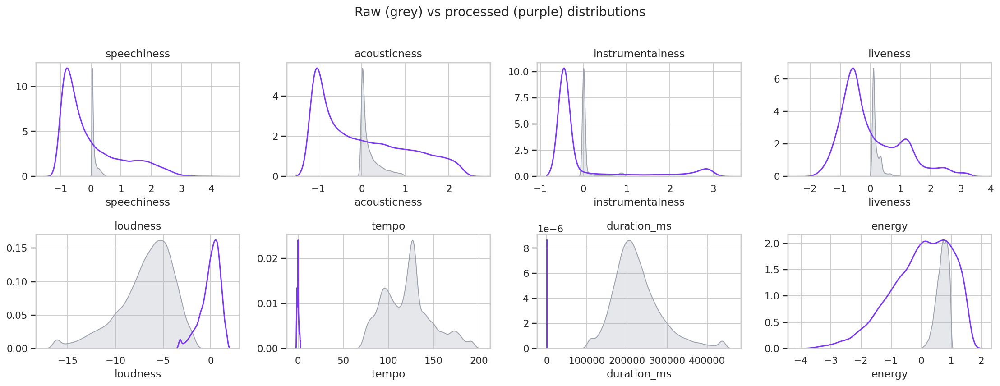

In [5]:
# skewness before / after the transformation, and the scaled matrix
X, scaler, bounds = rs.build_features(df)
raw_skew = df[rs.AUDIO_FEATURES].skew()
Xdf = pd.DataFrame(X, columns=rs.AUDIO_FEATURES)
sk = pd.DataFrame({"skew_before": raw_skew, "skew_after": Xdf.skew()}).round(2)
display(sk)
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, c in zip(axes.ravel(), rs.SKEWED + ["loudness", "tempo", "duration_ms", "energy"]):
    sns.kdeplot(df[c].clip(*(bounds.get(c, (None, None)))) if c in bounds else df[c], ax=ax, color="#9CA3AF", fill=True, label="raw")
    ax2 = ax.twinx(); sns.kdeplot(Xdf[c], ax=ax2, color="#7C3AED", label="processed"); ax2.set_ylabel(""); ax2.set_yticks([])
    ax.set_title(c); ax.set_ylabel("")
fig.suptitle("Raw (grey) vs processed (purple) distributions", y=1.02)
savefig("01_preprocessing_distributions")

**Insights.** Cleaning turns 32,833 rows into **26,222 unique songs**. The loss comes almost entirely from songs that sit in several playlists (4,477 repeated track ids) and about 2,100 re-releases with the same title and artist. 1,526 songs (5.8%) appear in playlists of more than one genre, an early sign that genre labels are cultural rather than purely acoustic. The log transform and winsorising pull in the long tails (loudness skew -1.18 to -0.93, duration 1.13 to 1.03) so no single outlier dominates the distance calculations.

## 3. Exploratory data analysis

### 3.1 Genres, sub-genres and playlists

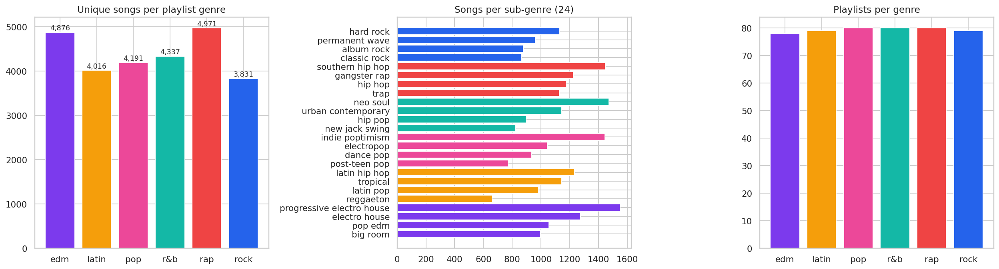

,playlist_name,playlist_genre,rows
195,Indie Poptimism,pop,308
276,Permanent Wave,rock,244
177,Hard Rock Workout,rock,219
143,Fitness Workout Electro | House | Dance | Prog...,edm,195
8,2020 Hits & 2019 Hits – Top Global Tracks 🔥🔥🔥,latin,194
340,Southern Hip Hop,rap,189
74,"Classic Rock 70s 80s 90s, Rock Classics - 70s ...",rock,182
415,Urban Contemporary,r&b,170
438,post teen pop,pop,166
437,permanent wave,rock,139


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
g = df.playlist_genre.value_counts().reindex(GENRES)
axes[0].bar(g.index, g.values, color=[GCOL[x] for x in g.index]); axes[0].set_title("Unique songs per playlist genre")
for i, v in enumerate(g.values): axes[0].text(i, v + 50, f"{v:,}", ha="center", fontsize=9)
sub = df.groupby(["playlist_genre", "playlist_subgenre"]).size().reset_index(name="n")
sub["playlist_genre"] = pd.Categorical(sub.playlist_genre, GENRES); sub = sub.sort_values(["playlist_genre", "n"])
axes[1].barh(sub.playlist_subgenre, sub.n, color=[GCOL[x] for x in sub.playlist_genre]); axes[1].set_title("Songs per sub-genre (24)")
pl = raw.groupby("playlist_genre").playlist_id.nunique().reindex(GENRES)
axes[2].bar(pl.index, pl.values, color=[GCOL[x] for x in pl.index]); axes[2].set_title("Playlists per genre")
savefig("02_genre_subgenre_counts")
top_pl = raw.groupby(["playlist_name", "playlist_genre"]).size().reset_index(name="rows").sort_values("rows", ascending=False).head(15)
display(top_pl)

### 3.2 Distribution of every audio feature

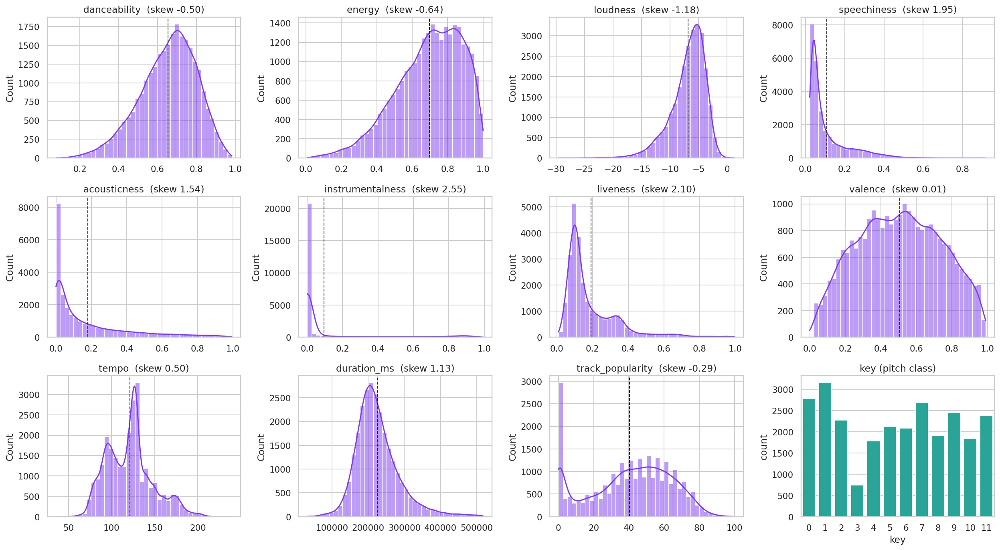

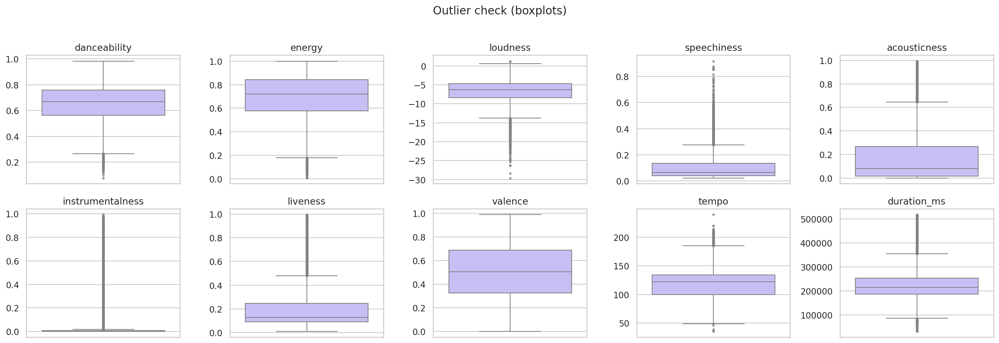

In [7]:
feats = rs.AUDIO_FEATURES + ["track_popularity"]
fig, axes = plt.subplots(3, 4, figsize=(18, 10))
for ax, c in zip(axes.ravel(), feats):
    sns.histplot(df[c], bins=40, kde=True, ax=ax, color="#7C3AED")
    ax.axvline(df[c].mean(), color="k", ls="--", lw=1); ax.set_title(f"{c}  (skew {df[c].skew():.2f})"); ax.set_xlabel("")
sns.countplot(x="key", data=df, ax=axes[2, 3], color="#14B8A6"); axes[2, 3].set_title("key (pitch class)")
savefig("03_feature_histograms")

fig, axes = plt.subplots(2, 5, figsize=(18, 6))
for ax, c in zip(axes.ravel(), rs.AUDIO_FEATURES):
    sns.boxplot(y=df[c], ax=ax, color="#C4B5FD", fliersize=2); ax.set_title(c); ax.set_ylabel("")
fig.suptitle("Outlier check (boxplots)", y=1.02)
savefig("04_boxplots_outliers")

### 3.3 Audio features by playlist genre

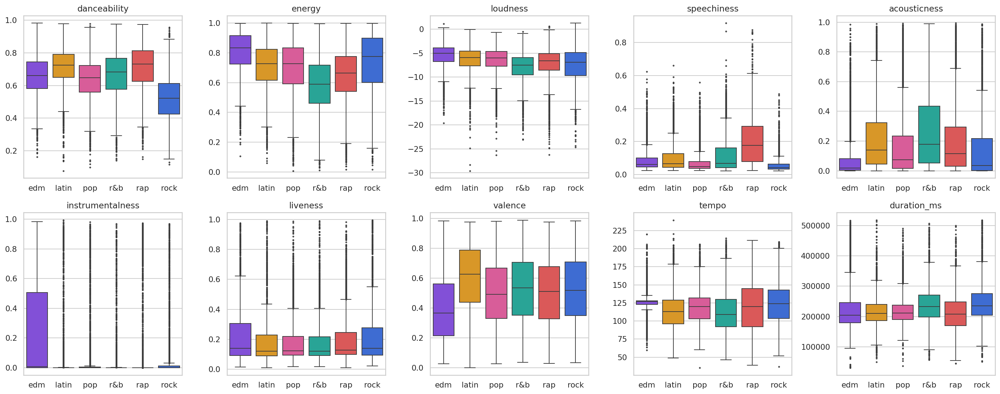

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,track_popularity
playlist_genre,,,,,,,,,,,
edm,0.659,0.805,-5.534,0.088,0.080,0.238,0.214,0.400,126.089,225346.959,32.396
latin,0.711,0.707,-6.458,0.102,0.217,0.052,0.182,0.605,118.848,217205.873,43.500
pop,0.635,0.700,-6.487,0.072,0.173,0.072,0.177,0.499,120.993,218504.695,44.317
r&b,0.665,0.586,-7.975,0.117,0.272,0.030,0.175,0.529,114.152,237663.791,39.249
rap,0.713,0.648,-7.166,0.198,0.200,0.086,0.191,0.501,120.695,211589.189,42.194
rock,0.518,0.731,-7.545,0.058,0.150,0.069,0.207,0.527,125.060,246575.368,42.370


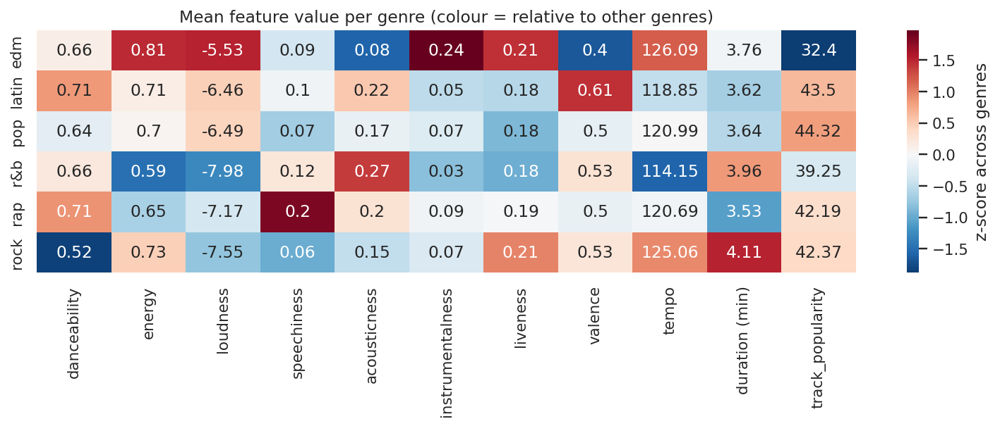

In [8]:
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for ax, c in zip(axes.ravel(), rs.AUDIO_FEATURES):
    sns.boxplot(data=df, x="playlist_genre", y=c, order=GENRES, palette=GCOL, ax=ax, fliersize=1.5)
    ax.set_title(c); ax.set_xlabel(""); ax.set_ylabel("")
savefig("05_features_by_genre_boxplots")

gm = df.groupby("playlist_genre")[rs.AUDIO_FEATURES + ["track_popularity"]].mean().reindex(GENRES)
display(gm.round(3))
gm.round(4).to_csv(TAB / "genre_feature_means.csv")
z = (gm - gm.mean()) / gm.std()
plt.figure(figsize=(11, 4.5)); ga = gm.copy(); ga["duration_ms"] = ga["duration_ms"] / 60000; ga = ga.rename(columns={"duration_ms": "duration (min)"})
sns.heatmap(z.rename(columns={"duration_ms": "duration (min)"}), annot=ga.round(2), fmt="", cmap="RdBu_r", center=0, cbar_kws={"label": "z-score across genres"})
plt.title("Mean feature value per genre (colour = relative to other genres)"); plt.ylabel("")
savefig("06_genre_feature_heatmap")

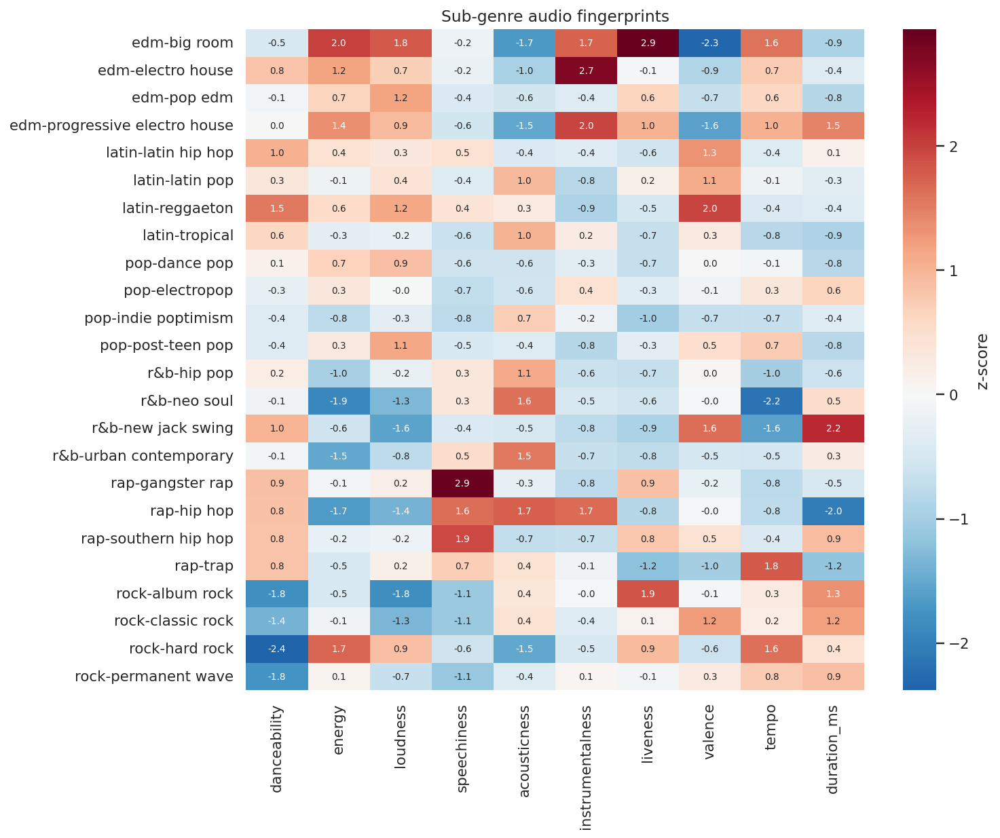

In [9]:
subm = df.groupby(["playlist_genre", "playlist_subgenre"])[rs.AUDIO_FEATURES].mean()
subz = (subm - subm.mean()) / subm.std()
plt.figure(figsize=(11, 9)); sns.heatmap(subz, cmap="RdBu_r", center=0, annot=True, fmt=".1f", annot_kws={"size": 7}, cbar_kws={"label": "z-score"})
plt.title("Sub-genre audio fingerprints"); plt.ylabel("")
savefig("07_subgenre_feature_heatmap")

### 3.4 Correlation matrix of features

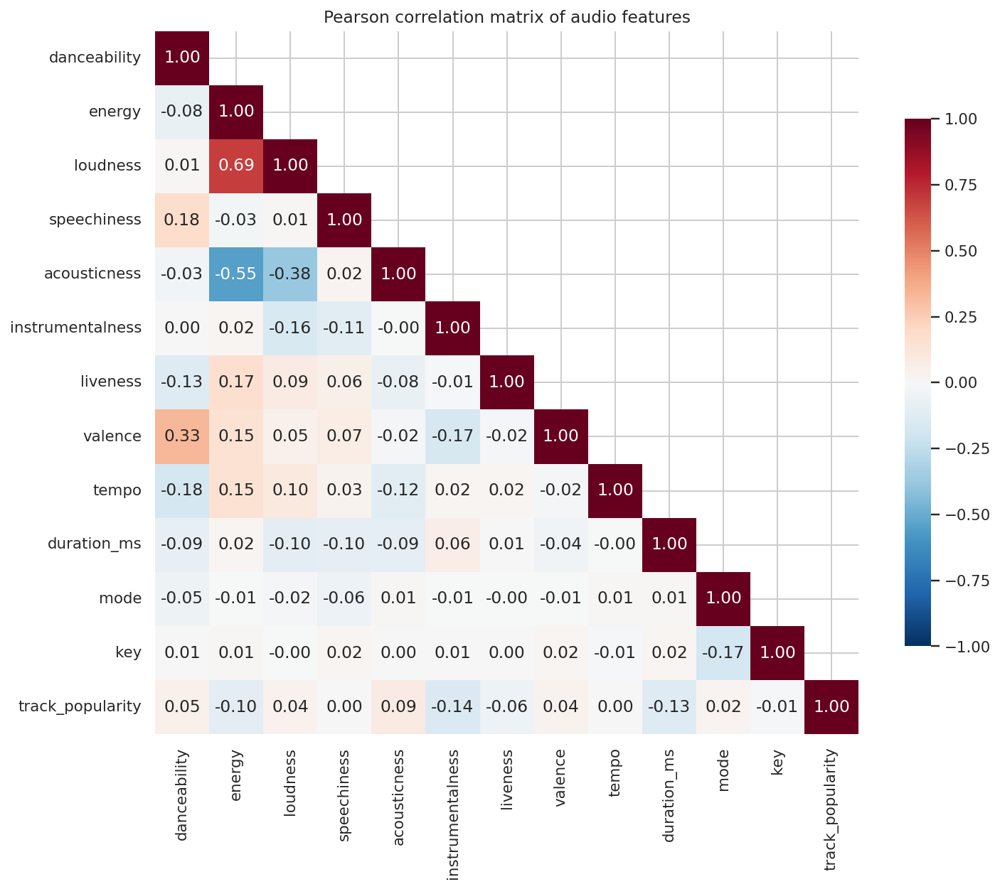

,feature_1,feature_2,r
27,loudness,energy,0.689
53,acousticness,energy,-0.551
54,acousticness,loudness,-0.379
91,valence,danceability,0.334
39,speechiness,danceability,0.183
104,tempo,danceability,-0.177
153,key,mode,-0.175
96,valence,instrumentalness,-0.171
79,liveness,energy,0.166
67,instrumentalness,loudness,-0.160


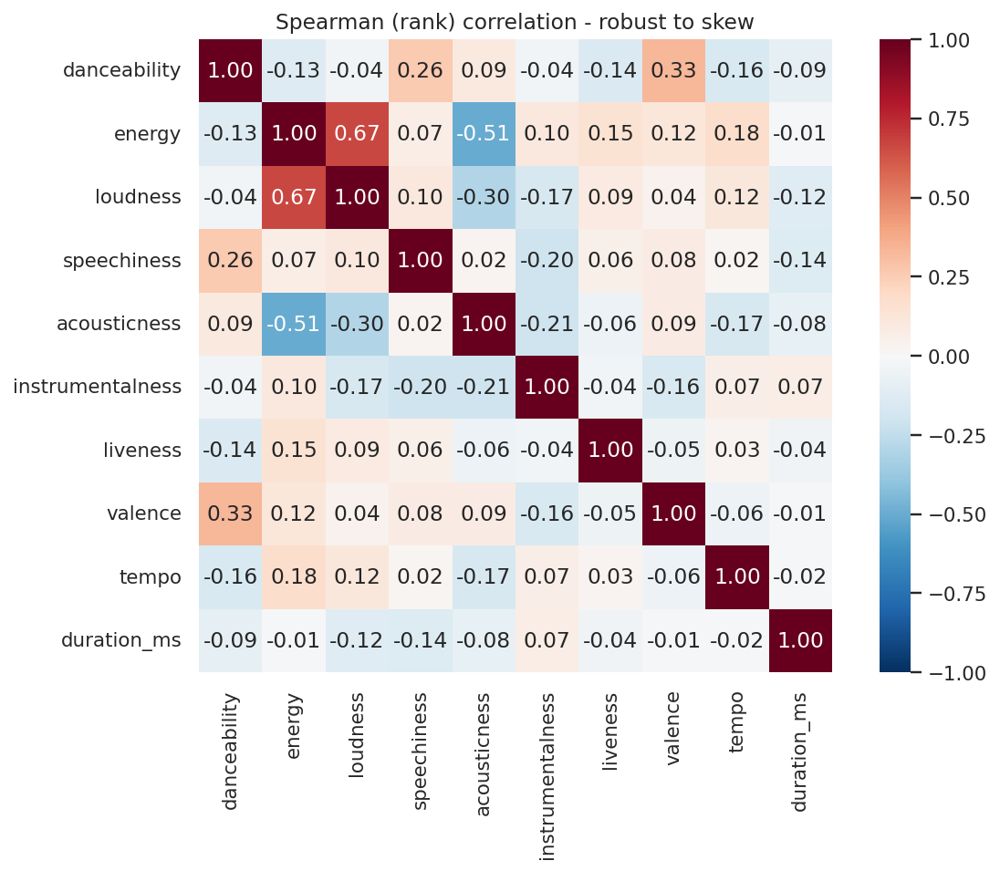

In [10]:
num = rs.AUDIO_FEATURES + ["mode", "key", "track_popularity"]
corr = df[num].corr()
mask = np.triu(np.ones_like(corr, bool), 1)
plt.figure(figsize=(11, 9))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, cbar_kws={"shrink": .75})
plt.title("Pearson correlation matrix of audio features")
savefig("08_correlation_matrix")
corr.round(3).to_csv(TAB / "correlation_matrix.csv")

pairs = corr.where(~mask & ~np.eye(len(corr), dtype=bool)).stack().rename("r").reset_index()
pairs.columns = ["feature_1", "feature_2", "r"]
pairs["abs_r"] = pairs.r.abs()
display(pairs.sort_values("abs_r", ascending=False).head(10).drop(columns="abs_r").round(3))

sp = df[rs.AUDIO_FEATURES].corr(method="spearman")
plt.figure(figsize=(9, 7)); sns.heatmap(sp, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True)
plt.title("Spearman (rank) correlation - robust to skew")
savefig("09_spearman_correlation")

**Insights.** Audio features are mostly independent of each other, which is why all ten are kept. The strongest relationships are **loudness-energy (r = +0.69)**, **energy-acousticness (-0.55)**, **loudness-acousticness (-0.38)** and **danceability-valence (+0.33)**: loud songs feel energetic, acoustic songs feel calm, danceable songs sound happier. Every feature has |r| <= 0.14 with popularity, so popularity cannot be predicted from audio alone and is analysed separately rather than used for clustering.

### 3.5 Relationships between features

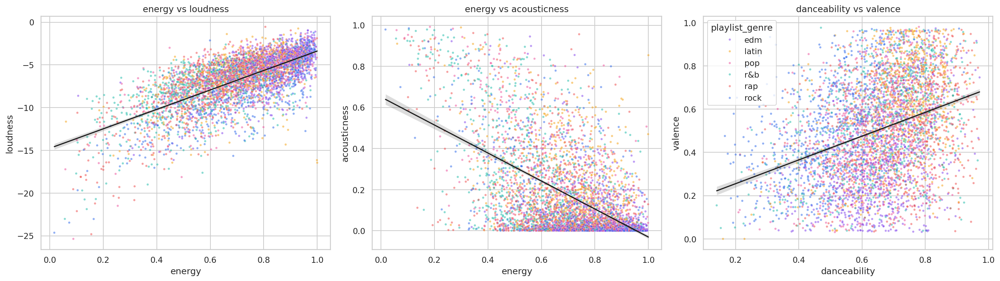

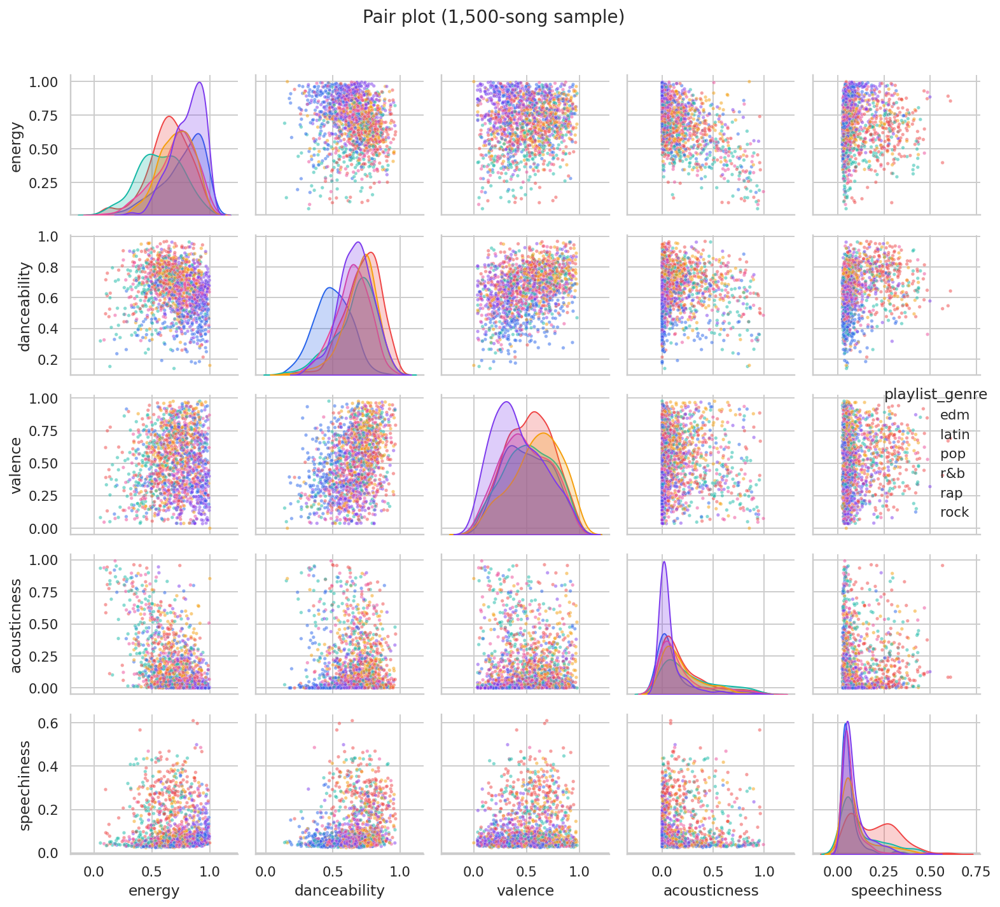

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
s = df.sample(5000, random_state=RS)
for ax, (a, b) in zip(axes, [("energy", "loudness"), ("energy", "acousticness"), ("danceability", "valence")]):
    sns.scatterplot(data=s, x=a, y=b, hue="playlist_genre", hue_order=GENRES, palette=GCOL, s=9, alpha=.5, ax=ax, legend=(ax is axes[2]))
    sns.regplot(data=s, x=a, y=b, scatter=False, color="k", line_kws={"lw": 1.5}, ax=ax); ax.set_title(f"{a} vs {b}")
savefig("10_feature_relationships")

pp = s.sample(1500, random_state=RS)[["energy", "danceability", "valence", "acousticness", "speechiness", "playlist_genre"]]
g = sns.pairplot(pp, hue="playlist_genre", hue_order=GENRES, palette=GCOL, plot_kws={"s": 8, "alpha": .5}, diag_kind="kde", height=2)
g.fig.suptitle("Pair plot (1,500-song sample)", y=1.02)
savefig("11_pairplot")

### 3.6 Popularity

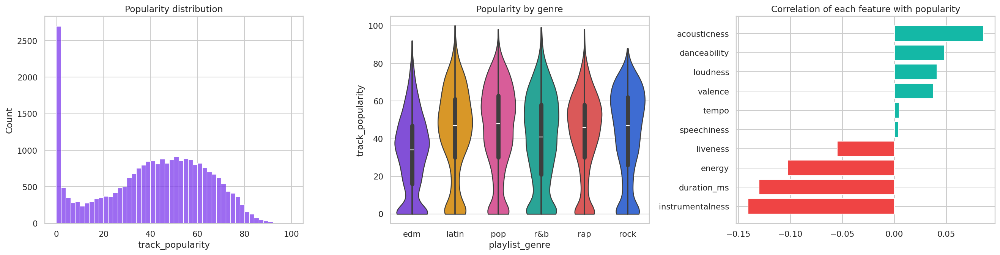

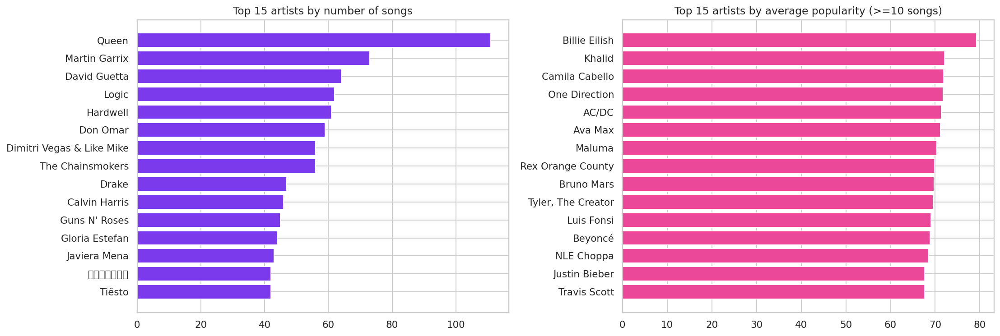

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
sns.histplot(df.track_popularity, bins=50, ax=axes[0], color="#7C3AED"); axes[0].set_title("Popularity distribution")
sns.violinplot(data=df, x="playlist_genre", y="track_popularity", order=GENRES, palette=GCOL, ax=axes[1], cut=0); axes[1].set_title("Popularity by genre")
pc = df[rs.AUDIO_FEATURES].corrwith(df.track_popularity).sort_values()
axes[2].barh(pc.index, pc.values, color=np.where(pc.values > 0, "#14B8A6", "#EF4444")); axes[2].set_title("Correlation of each feature with popularity")
savefig("12_popularity")

art = df.groupby("track_artist").agg(songs=("track_id", "size"), avg_pop=("track_popularity", "mean"))
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
a1 = art.sort_values("songs", ascending=False).head(15)[::-1]; axes[0].barh(a1.index, a1.songs, color="#7C3AED"); axes[0].set_title("Top 15 artists by number of songs")
a2 = art[art.songs >= 10].sort_values("avg_pop", ascending=False).head(15)[::-1]; axes[1].barh(a2.index, a2.avg_pop, color="#EC4899"); axes[1].set_title("Top 15 artists by average popularity (>=10 songs)")
savefig("13_top_artists")

### 3.7 Time trends, key and mode

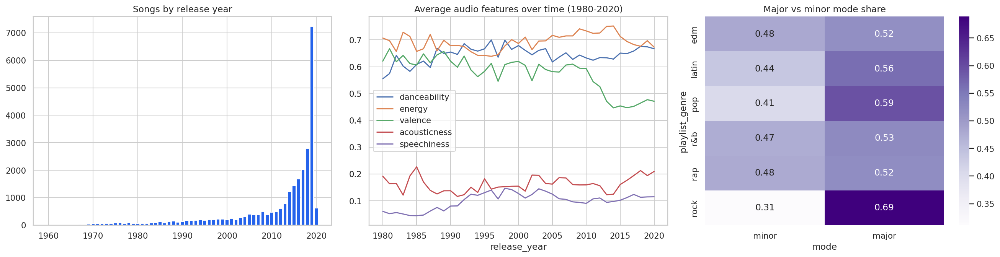

In [13]:
yr = df[df.release_year.between(1980, 2020)]
trend = yr.groupby("release_year")[["danceability", "energy", "valence", "acousticness", "speechiness"]].mean()
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
cnt = df.release_year.dropna().astype(int).value_counts().sort_index(); cnt = cnt[cnt.index >= 1960]
axes[0].bar(cnt.index, cnt.values, color="#2563EB"); axes[0].set_title("Songs by release year")
trend.plot(ax=axes[1]); axes[1].set_title("Average audio features over time (1980-2020)")
sns.heatmap(pd.crosstab(df.playlist_genre, df["mode"], normalize="index").reindex(GENRES).rename(columns={0: "minor", 1: "major"}), annot=True, fmt=".2f", cmap="Purples", ax=axes[2]); axes[2].set_title("Major vs minor mode share")
savefig("14_time_key_mode")

### 3.8 Genre fingerprints (radar) and genre overlap

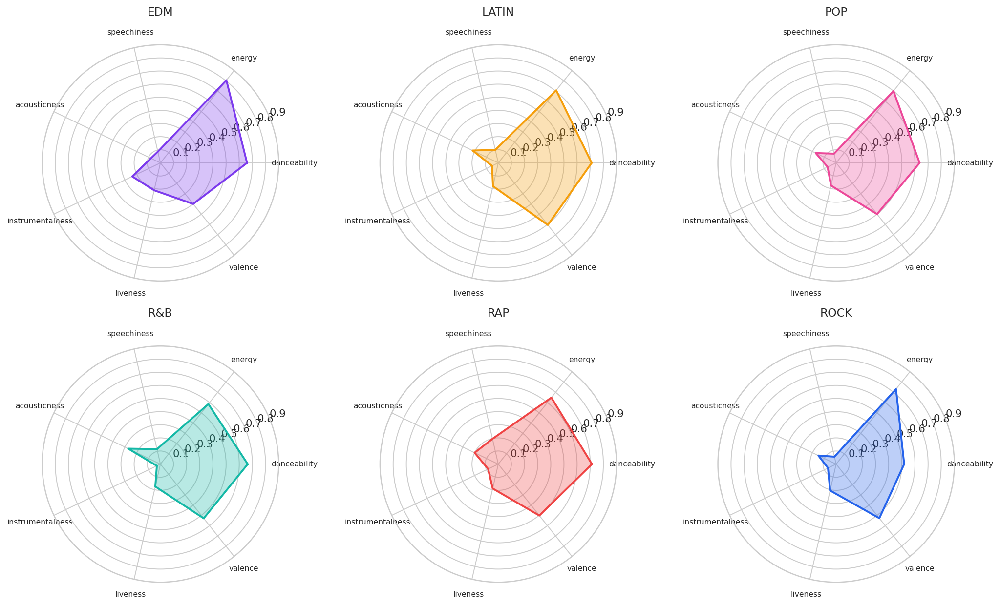

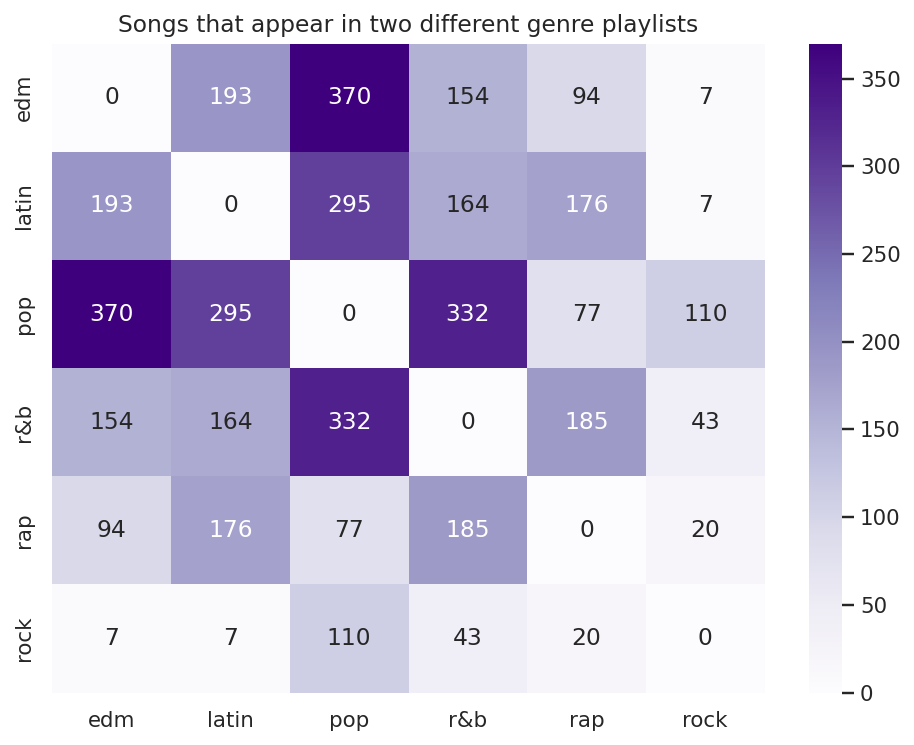

In [14]:
radar_f = ["danceability", "energy", "speechiness", "acousticness", "instrumentalness", "liveness", "valence"]
ang = np.linspace(0, 2 * np.pi, len(radar_f), endpoint=False).tolist(); ang += ang[:1]
fig, axes = plt.subplots(2, 3, figsize=(15, 9), subplot_kw=dict(polar=True))
rm = df.groupby("playlist_genre")[radar_f].mean()
for ax, gname in zip(axes.ravel(), GENRES):
    v = rm.loc[gname].tolist(); v += v[:1]
    ax.plot(ang, v, color=GCOL[gname], lw=2); ax.fill(ang, v, color=GCOL[gname], alpha=.3)
    ax.set_xticks(ang[:-1]); ax.set_xticklabels(radar_f, fontsize=8); ax.set_ylim(0, .9); ax.set_title(gname.upper(), y=1.1)
savefig("15_genre_radar")

from itertools import combinations
co = pd.DataFrame(0, index=GENRES, columns=GENRES)
for gl in df.all_genres.values:
    for a, b in combinations(gl, 2): co.loc[a, b] += 1; co.loc[b, a] += 1
plt.figure(figsize=(7, 5.5)); sns.heatmap(co, annot=True, fmt="d", cmap="Purples"); plt.title("Songs that appear in two different genre playlists")
savefig("16_genre_overlap")

**Insights.** **Genres differ in clear but overlapping ways.** Rap has by far the highest speechiness (0.20 vs <= 0.12 elsewhere); EDM is the most energetic (0.81), loudest (-5.5 dB), most instrumental (0.24) and least positive (valence 0.40); R&B is the calmest (energy 0.59) and most acoustic (0.27); Latin is the happiest (valence 0.61) and among the most danceable; rock has the lowest danceability (0.52) and the highest share of major-key songs (69%). Pop is the most popular genre (44.3) and EDM the least (32.4). **Time:** 60% of songs were released in 2015 or later (7,232 in 2019 alone). Average valence fell from about 0.62 (1980-2010) to 0.48 in 2019, while speechiness roughly doubled (0.06 to 0.115) and danceability rose (0.56 to 0.67). **Popularity:** median 43, 8.6% of songs score 0; Queen has the most songs (111) and Billie Eilish the highest average popularity (79).

## 4. Dimensionality reduction

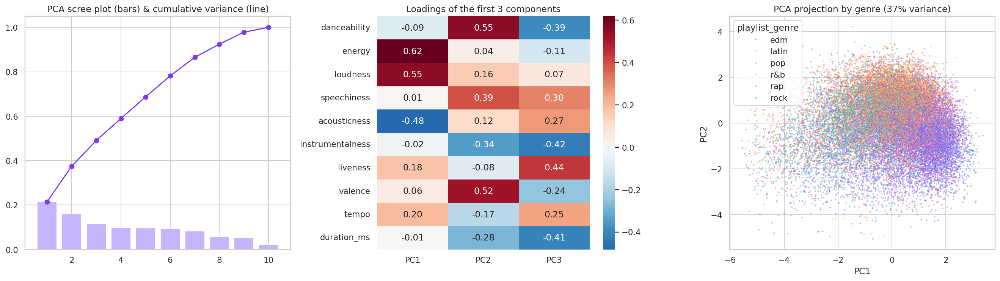

{'pca_var_2': 0.375, 'pca_var_4': 0.589, 'pca_components_80pct': 7}


In [15]:
from sklearn.decomposition import PCA
pca_full = PCA(random_state=RS).fit(X)
ev = pca_full.explained_variance_ratio_
pca = PCA(2, random_state=RS).fit(X); P = pca.transform(X)
load = pd.DataFrame(pca_full.components_[:3].T, index=rs.AUDIO_FEATURES, columns=["PC1", "PC2", "PC3"])
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
axes[0].bar(range(1, len(ev) + 1), ev, color="#C4B5FD"); axes[0].plot(range(1, len(ev) + 1), ev.cumsum(), "o-", color="#7C3AED"); axes[0].set_title("PCA scree plot (bars) & cumulative variance (line)")
sns.heatmap(load, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[1]); axes[1].set_title("Loadings of the first 3 components")
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=df.playlist_genre, hue_order=GENRES, palette=GCOL, s=5, alpha=.4, ax=axes[2]); axes[2].set_title(f"PCA projection by genre ({ev[:2].sum():.0%} variance)")
axes[2].set_xlabel("PC1"); axes[2].set_ylabel("PC2")
savefig("17_pca")
METRICS["pca_var_2"] = float(ev[:2].sum()); METRICS["pca_var_4"] = float(ev[:4].sum()); METRICS["pca_components_80pct"] = int((ev.cumsum() < .8).sum() + 1)
print({k: round(v, 3) for k, v in METRICS.items()})

t-SNE 45s


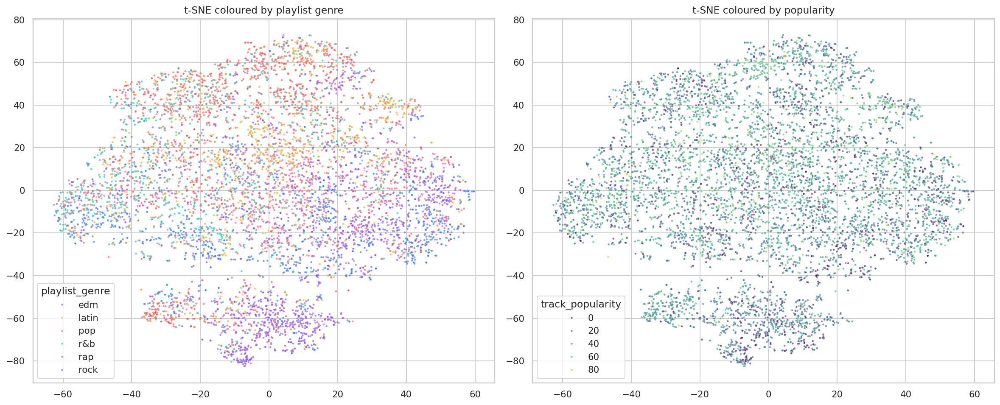

In [16]:
from sklearn.manifold import TSNE
ts = df.sample(7000, random_state=RS).index
t0 = time.time(); T = TSNE(2, perplexity=40, init="pca", random_state=RS).fit_transform(X[ts]); print(f"t-SNE {time.time()-t0:.0f}s")
fig, axes = plt.subplots(1, 2, figsize=(17, 7))
sns.scatterplot(x=T[:, 0], y=T[:, 1], hue=df.playlist_genre.iloc[ts], hue_order=GENRES, palette=GCOL, s=6, alpha=.6, ax=axes[0]); axes[0].set_title("t-SNE coloured by playlist genre")
sns.scatterplot(x=T[:, 0], y=T[:, 1], hue=df.track_popularity.iloc[ts], palette="viridis", s=6, alpha=.6, ax=axes[1]); axes[1].set_title("t-SNE coloured by popularity")
savefig("18_tsne_genre")

**Insights.** The first two principal components explain only **37.5%** of the variance, four explain 58.9% and **seven** are needed to reach 80%, so information is spread across the features rather than concentrated in one or two directions. PC1 is an *intensity* axis (energy and loudness against acousticness) and PC2 a *groove/positivity* axis (danceability, valence, speechiness). In both PCA and t-SNE the genres form overlapping clouds with only a gradual drift between them (rap towards the speechiness side, EDM and rock towards high energy), so we should expect clusters to be soft rather than sharply separated.

## 5. Clustering - model selection

### 5.1 Choosing *k* for K-Means

,inertia,silhouette,calinski_harabasz,davies_bouldin,ARI_vs_genre,NMI_vs_genre
k,,,,,,
2,225397.467,0.150,4283.534,2.308,0.029,0.040
3,202852.593,0.122,3836.674,2.212,0.076,0.091
4,186795.061,0.128,3528.847,2.041,0.073,0.101
5,173795.468,0.123,3334.709,1.943,0.086,0.120
6,166032.769,0.115,3037.539,1.912,0.075,0.105
7,159136.795,0.117,2830.210,1.845,0.068,0.105
8,152760.721,0.124,2683.349,1.839,0.071,0.111
9,147244.882,0.126,2558.536,1.784,0.066,0.106
10,142739.988,0.116,2437.856,1.848,0.064,0.107


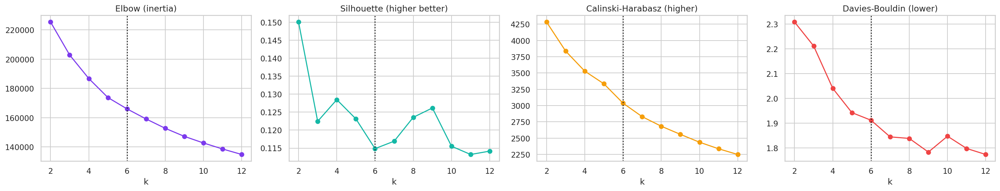

In [17]:
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score, adjusted_rand_score, normalized_mutual_info_score
rows = []
for k in range(2, 13):
    km = KMeans(k, n_init=10, random_state=RS).fit(X); l = km.labels_
    rows.append(dict(k=k, inertia=km.inertia_, silhouette=silhouette_score(X, l, sample_size=8000, random_state=RS),
                     calinski_harabasz=calinski_harabasz_score(X, l), davies_bouldin=davies_bouldin_score(X, l),
                     ARI_vs_genre=adjusted_rand_score(df.playlist_genre, l), NMI_vs_genre=normalized_mutual_info_score(df.playlist_genre, l)))
ksel = pd.DataFrame(rows).set_index("k"); display(ksel.round(3)); ksel.round(4).to_csv(TAB / "kmeans_k_selection.csv")
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (c, t, col) in zip(axes, [("inertia", "Elbow (inertia)", "#7C3AED"), ("silhouette", "Silhouette (higher better)", "#14B8A6"),
                                  ("calinski_harabasz", "Calinski-Harabasz (higher)", "#F59E0B"), ("davies_bouldin", "Davies-Bouldin (lower)", "#EF4444")]):
    ax.plot(ksel.index, ksel[c], "o-", color=col); ax.set_title(t); ax.set_xlabel("k"); ax.axvline(6, ls=":", color="k")
savefig("19_kmeans_k_selection")

**Choice of k = 6.** The metrics do not show a sharp optimum: inertia decays smoothly (no clear elbow) and silhouette stays in a narrow 0.11-0.15 band for every k > 2. That is a real property of the data (audio features vary continuously across songs), not a modelling failure. We therefore choose **k = 6** because (i) Davies-Bouldin and inertia have already flattened by this point, (ii) it gives clusters that are large enough to be interpreted and to drive recommendations, and (iii) it matches the six-genre taxonomy so the clusters can be compared directly with `playlist_genre`.

### 5.2 Comparing clustering algorithms

In [18]:
K = 6
sub = np.random.RandomState(RS).choice(len(X), 8000, replace=False)
res = {}
res["K-Means"] = KMeans(K, n_init=20, random_state=RS).fit_predict(X)
res["Gaussian Mixture"] = GaussianMixture(K, covariance_type="full", n_init=3, random_state=RS).fit_predict(X)
agg_lab = np.full(len(X), -1); agg_lab[sub] = AgglomerativeClustering(K, linkage="ward").fit_predict(X[sub]); res["Agglomerative (Ward, 8k sample)"] = agg_lab
db_lab = DBSCAN(eps=1.2, min_samples=30).fit_predict(X); res["DBSCAN (eps=1.2)"] = db_lab
comp = []
for name, l in res.items():
    m = l >= 0; n_cl = len(set(l[m])); noise = 100 * (1 - m.mean()) if name.startswith("DBSCAN") else 0.0
    if n_cl < 2: comp.append(dict(model=name, clusters=n_cl)); continue
    idx = np.where(m)[0]; ss = np.random.RandomState(RS).choice(idx, min(8000, len(idx)), replace=False)
    comp.append(dict(model=name, clusters=n_cl, noise_pct=noise,
                     silhouette=silhouette_score(X[ss], l[ss]), davies_bouldin=davies_bouldin_score(X[m], l[m]),
                     calinski_harabasz=calinski_harabasz_score(X[m], l[m]),
                     ARI_vs_genre=adjusted_rand_score(df.playlist_genre[m], l[m]), NMI_vs_genre=normalized_mutual_info_score(df.playlist_genre[m], l[m])))
comp = pd.DataFrame(comp).set_index("model"); display(comp.round(3)); comp.round(4).to_csv(TAB / "algorithm_comparison.csv")

,clusters,noise_pct,silhouette,davies_bouldin,calinski_harabasz,ARI_vs_genre,NMI_vs_genre
model,,,,,,,
K-Means,6,0.000,0.115,1.918,3037.730,0.075,0.105
Gaussian Mixture,6,0.000,-0.008,4.436,978.019,0.057,0.076
"Agglomerative (Ward, 8k sample)",6,0.000,0.063,2.283,620.253,0.055,0.083
DBSCAN (eps=1.2),4,52.265,0.133,1.088,514.318,-0.004,0.053


**Insights.** **K-Means is the best usable model.** It scores a silhouette of 0.115 and the best Calinski-Harabasz and Davies-Bouldin among the methods that label every song. Gaussian Mixture (silhouette about 0) shows that its components overlap heavily; Ward clustering on an 8,000-song sample is weaker (0.063). DBSCAN has the highest silhouette (0.13) only because it discards **52% of songs as noise** and finds four dense cores, which is unusable for a recommender that must cover every track. All ARI values against genre are below 0.08, so **audio clusters are not simply the playlist genres** - which is the interesting result of the project.

## 6. Final model: K-Means (k = 6) - cluster profiles

In [19]:
rec = rs.SpotifyRecommender(k=K, random_state=RS).fit(df)
df = rec.df                      # now has the 'cluster' column
METRICS.update(k=K, n_songs=len(df), silhouette_final=float(silhouette_score(X, df.cluster, sample_size=10000, random_state=RS)),
               davies_bouldin_final=float(davies_bouldin_score(X, df.cluster)),
               ARI_vs_genre=float(adjusted_rand_score(df.playlist_genre, df.cluster)),
               NMI_vs_genre=float(normalized_mutual_info_score(df.playlist_genre, df.cluster)))
print({k: round(v, 3) if isinstance(v, float) else v for k, v in METRICS.items()})
prof = df.groupby("cluster")[rs.AUDIO_FEATURES + ["track_popularity"]].mean()
prof["songs"] = df.cluster.value_counts().sort_index(); prof["share_%"] = 100 * prof.songs / len(df)
display(prof.round(3)); prof.round(4).to_csv(TAB / "cluster_profiles.csv")

{'pca_var_2': 0.375, 'pca_var_4': 0.589, 'pca_components_80pct': 7, 'k': 6, 'n_songs': 26222, 'silhouette_final': 0.116, 'davies_bouldin_final': 1.918, 'ARI_vs_genre': 0.075, 'NMI_vs_genre': 0.105}


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,track_popularity,songs,share_%
cluster,,,,,,,,,,,,,
0,0.664,0.799,-6.801,0.070,0.058,0.663,0.181,0.402,125.650,256181.222,29.600,2650,10.106
1,0.623,0.814,-5.347,0.095,0.090,0.021,0.437,0.527,122.026,221051.919,39.014,3855,14.701
2,0.738,0.722,-6.288,0.066,0.160,0.010,0.122,0.687,113.773,220922.517,43.318,6548,24.971
3,0.529,0.785,-5.381,0.073,0.061,0.012,0.139,0.362,135.508,228757.165,40.441,4782,18.237
4,0.597,0.418,-10.697,0.066,0.497,0.121,0.155,0.383,112.776,226071.512,42.264,4039,15.403
5,0.737,0.653,-7.007,0.287,0.205,0.010,0.174,0.553,119.934,213747.945,42.340,4348,16.581


In [20]:
# automatic descriptive label = the two most distinctive features of each cluster
zc = (prof[rs.AUDIO_FEATURES] - prof[rs.AUDIO_FEATURES].mean()) / prof[rs.AUDIO_FEATURES].std()
def auto_name(r):
    top = r.abs().sort_values(ascending=False).head(2).index
    return " / ".join(("high " if r[c] > 0 else "low ") + c for c in top)
auto = zc.apply(auto_name, axis=1); display(auto.to_frame("most distinctive features"))

,most distinctive features
cluster,
0,high instrumentalness / high duration_ms
1,high liveness / high loudness
2,high valence / high danceability
3,high tempo / low danceability
4,high acousticness / low loudness
5,high speechiness / high danceability


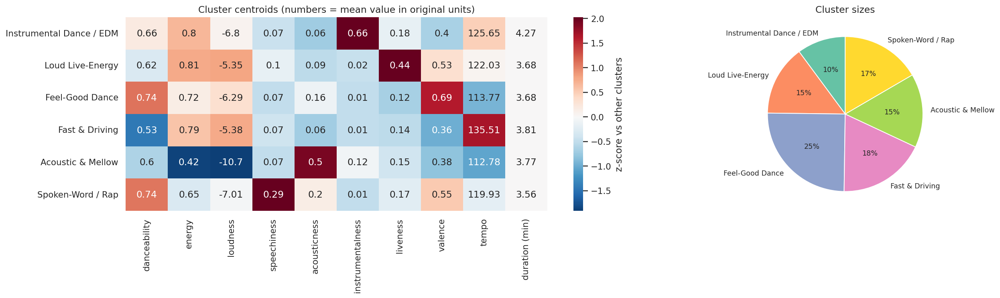

In [21]:
CLUSTER_NAMES = json.load(open("../outputs/tables/cluster_names.json")) if Path("../outputs/tables/cluster_names.json").exists() else {}
CLUSTER_NAMES = {int(k): v for k, v in CLUSTER_NAMES.items()} or {c: f"Cluster {c}" for c in range(K)}
df["cluster_name"] = df.cluster.map(CLUSTER_NAMES)
CPAL = sns.color_palette("Set2", K)
fig, axes = plt.subplots(1, 2, figsize=(19, 5.5), gridspec_kw={"width_ratios": [1.3, 1]})
def nice(d):  # duration in minutes so annotations fit
    d = d.copy(); d["duration_ms"] = d["duration_ms"] / 60000; return d.rename(columns={"duration_ms": "duration (min)"})
sns.heatmap(nice(zc).rename(index=CLUSTER_NAMES), annot=nice(prof[rs.AUDIO_FEATURES]).round(2).values, fmt="", cmap="RdBu_r", center=0, ax=axes[0], cbar_kws={"label": "z-score vs other clusters"})
axes[0].set_title("Cluster centroids (numbers = mean value in original units)"); axes[0].set_ylabel("")
sizes = df.cluster.value_counts().sort_index(); axes[1].pie(sizes, labels=[CLUSTER_NAMES[i] for i in sizes.index], colors=CPAL, autopct="%1.0f%%", startangle=90, textprops={"fontsize": 9}); axes[1].set_title("Cluster sizes")
savefig("20_cluster_profiles")

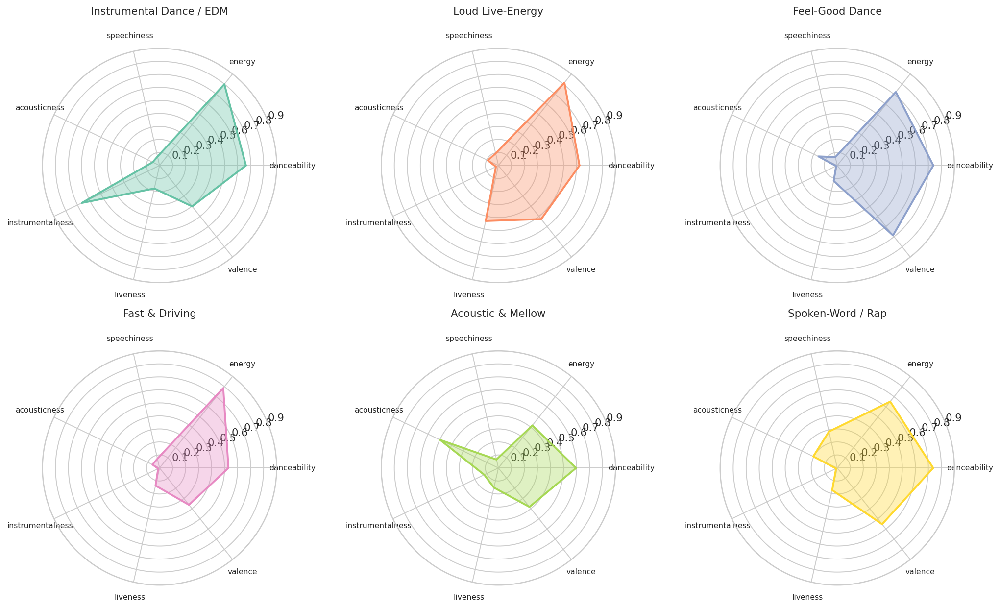

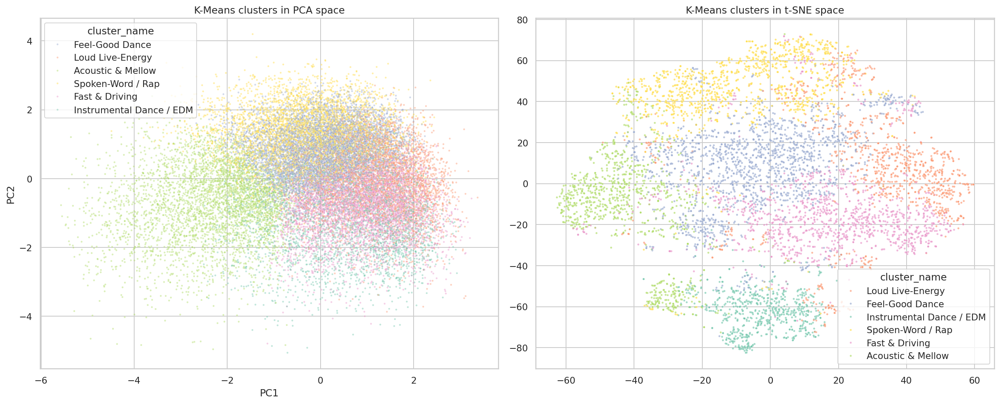

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9), subplot_kw=dict(polar=True))
rc = df.groupby("cluster")[radar_f].mean()
for ax, c in zip(axes.ravel(), range(K)):
    v = rc.loc[c].tolist(); v += v[:1]
    ax.plot(ang, v, color=CPAL[c], lw=2); ax.fill(ang, v, color=CPAL[c], alpha=.35)
    ax.set_xticks(ang[:-1]); ax.set_xticklabels(radar_f, fontsize=8); ax.set_ylim(0, .9); ax.set_title(CLUSTER_NAMES[c], y=1.12, fontsize=11)
savefig("21_cluster_radar")

P = rec.pca.transform(rec.X)
fig, axes = plt.subplots(1, 2, figsize=(17, 7))
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=df.cluster_name, palette=dict(zip(CLUSTER_NAMES.values(), CPAL)), s=5, alpha=.4, ax=axes[0]); axes[0].set_title("K-Means clusters in PCA space"); axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")
sns.scatterplot(x=T[:, 0], y=T[:, 1], hue=df.cluster_name.iloc[ts], palette=dict(zip(CLUSTER_NAMES.values(), CPAL)), s=6, alpha=.6, ax=axes[1]); axes[1].set_title("K-Means clusters in t-SNE space")
savefig("22_cluster_scatter")

**Insights.** **Six sonic families emerge** (silhouette 0.116, Davies-Bouldin 1.92): **Feel-Good Dance** (25%, most danceable and happiest, valence 0.69), **Fast & Driving** (18%, fastest at 136 BPM, least danceable, dark mood), **Acoustic & Mellow** (15%, acousticness 0.50, energy 0.42, quietest at -10.7 dB), **Spoken-Word / Rap** (17%, speechiness 0.29, four times the average), **Loud Live-Energy** (15%, loudest at -5.3 dB and by far the highest liveness, 0.44) and **Instrumental Dance / EDM** (10%, instrumentalness 0.66, and the lowest average popularity, 29.6). The low silhouette reflects a continuum of styles, so clusters are best read as *neighbourhoods* of the audio space with soft borders.

## 7. Clusters according to *playlist genre* and *sub-genre*

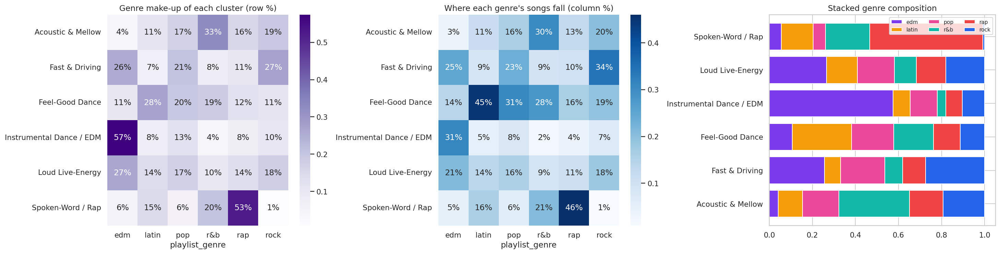

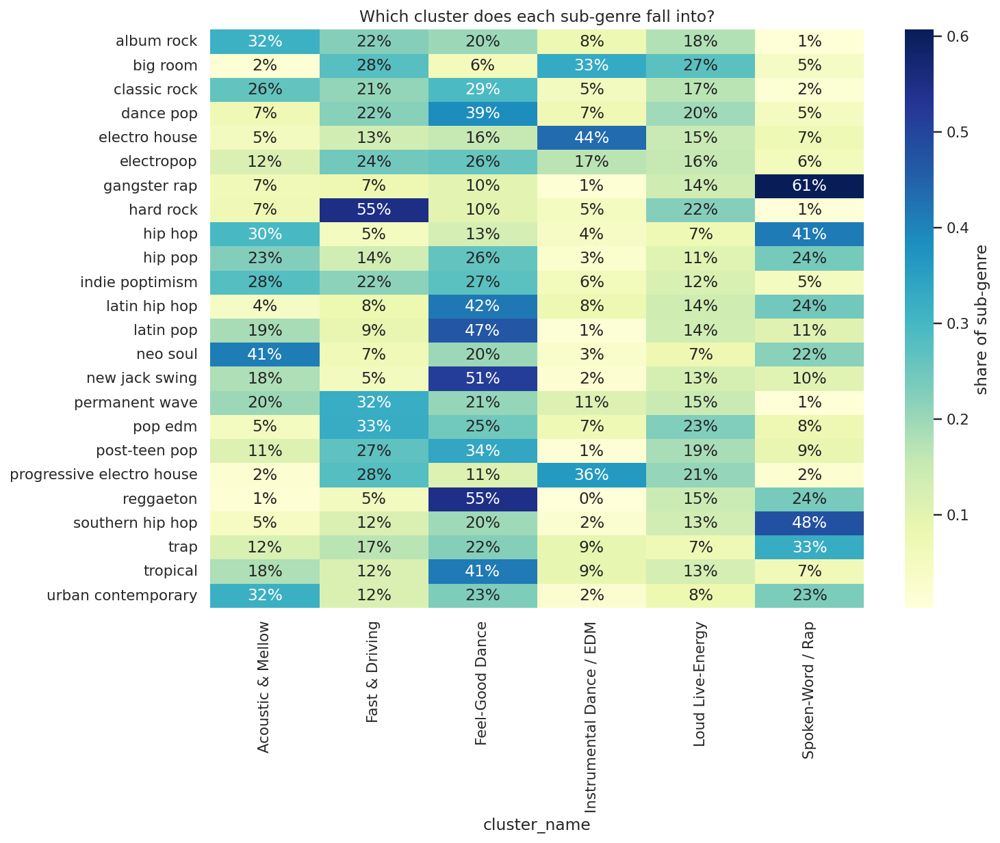

In [23]:
ct = pd.crosstab(df.cluster_name, df.playlist_genre)[GENRES]
fig, axes = plt.subplots(1, 3, figsize=(21, 5.5))
sns.heatmap(ct.div(ct.sum(1), axis=0), annot=True, fmt=".0%", cmap="Purples", ax=axes[0]); axes[0].set_title("Genre make-up of each cluster (row %)"); axes[0].set_ylabel("")
sns.heatmap(ct.div(ct.sum(0), axis=1), annot=True, fmt=".0%", cmap="Blues", ax=axes[1]); axes[1].set_title("Where each genre's songs fall (column %)"); axes[1].set_ylabel("")
(ct.div(ct.sum(1), axis=0)).plot(kind="barh", stacked=True, color=[GCOL[g] for g in GENRES], ax=axes[2], width=.8); axes[2].set_title("Stacked genre composition"); axes[2].set_ylabel(""); axes[2].legend(ncol=3, fontsize=8)
savefig("23_clusters_vs_genre")
ct.to_csv(TAB / "cluster_vs_genre_counts.csv")

cs = pd.crosstab(df.playlist_subgenre, df.cluster_name, normalize="index")
plt.figure(figsize=(11, 9)); sns.heatmap(cs, annot=True, fmt=".0%", cmap="YlGnBu", cbar_kws={"label": "share of sub-genre"}); plt.title("Which cluster does each sub-genre fall into?"); plt.ylabel("")
savefig("24_clusters_vs_subgenre")

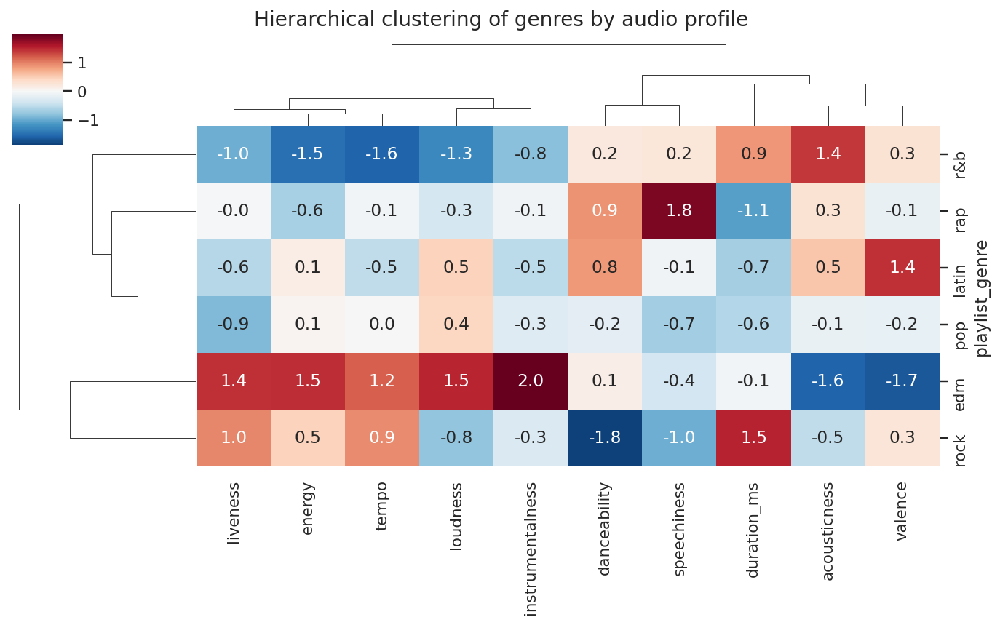

In [24]:
# genre-level hierarchical view: how similar are the six genres to each other?
gz = (gm[rs.AUDIO_FEATURES] - gm[rs.AUDIO_FEATURES].mean()) / gm[rs.AUDIO_FEATURES].std()
cg = sns.clustermap(gz, cmap="RdBu_r", center=0, annot=True, fmt=".1f", figsize=(10, 6), method="ward")
cg.fig.suptitle("Hierarchical clustering of genres by audio profile", y=1.02)
cg.savefig(FIG / "25_genre_clustermap.png", dpi=140, bbox_inches="tight"); display(Image(filename=str(FIG / "25_genre_clustermap.png"))); plt.close("all")

**Insights.** Genre and sound are only loosely linked (ARI 0.075, NMI 0.105). Two clusters are genre-leaning: **Spoken-Word / Rap** is 53% rap (2,287 of 4,348 songs) and only 37 rock songs, and **Instrumental Dance / EDM** is 57% EDM. The rest mix genres: the largest cluster, Feel-Good Dance, is 28% Latin, 20% pop, 19% R&B, 12% rap, 11% rock and 11% EDM, and Fast & Driving splits almost evenly between rock (27%) and EDM (26%). Playlist genres come from how a playlist is curated (culture, era, mood), not only how songs sound; for example, the same cluster holds Latin, pop and R&B songs that share a danceable, upbeat feel. The genre dendrogram agrees: it first separates a high-energy pair (**EDM and rock**, both loud, fast and live) from the other four, within which rap, Latin and pop group together and the mellow, acoustic **R&B** joins last.

## 8. Clusters according to *playlist name*

Each playlist is summarised by the average audio profile of its songs (using every row of the original file, so a playlist keeps all its songs), then the playlists themselves are clustered.

Playlist names: 449 | names spanning more than one genre: 5


{2: 0.2, 3: 0.196, 4: 0.217, 5: 0.22, 6: 0.202, 7: 0.212, 8: 0.196, 9: 0.21, 10: 0.219}


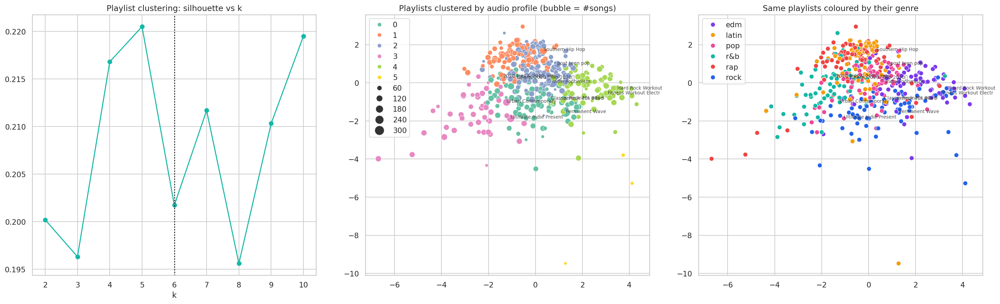

genre,edm,latin,pop,r&b,rap,rock
pl_cluster,,,,,,
0,4,4,11,22,1,46
1,0,7,1,16,62,0
2,20,59,47,9,4,1
3,1,4,9,24,5,7
4,53,2,5,1,5,16
5,0,1,0,0,0,2


In [25]:
rr = raw.dropna(subset=["track_name"]).copy()
rr = rr[(rr.tempo > 0) & (rr.duration_ms >= 30000) & (rr.loudness > -30)]
pl = rr.groupby("playlist_name").agg(**{c: (c, "mean") for c in rs.AUDIO_FEATURES}, songs=("track_id", "size"),
        genre=("playlist_genre", lambda s: s.mode().iat[0]), n_genres=("playlist_genre", "nunique"))
print("Playlist names:", len(pl), "| names spanning more than one genre:", int((pl.n_genres > 1).sum()))
PX = pd.DataFrame(rs.StandardScaler().fit_transform(pl[rs.AUDIO_FEATURES]), index=pl.index, columns=rs.AUDIO_FEATURES)
sil = {k: silhouette_score(PX, KMeans(k, n_init=20, random_state=RS).fit_predict(PX)) for k in range(2, 11)}
print({k: round(v, 3) for k, v in sil.items()})
PK = 6
pl["pl_cluster"] = KMeans(PK, n_init=30, random_state=RS).fit_predict(PX)
pp_ = PCA(2, random_state=RS).fit(PX); PP = pp_.transform(PX)
fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))
axes[0].plot(list(sil), list(sil.values()), "o-", color="#14B8A6"); axes[0].axvline(PK, ls=":", color="k"); axes[0].set_title("Playlist clustering: silhouette vs k"); axes[0].set_xlabel("k")
sns.scatterplot(x=PP[:, 0], y=PP[:, 1], hue=pl.pl_cluster.values, palette="Set2", size=pl.songs.values, sizes=(15, 200), ax=axes[1], legend="brief"); axes[1].set_title("Playlists clustered by audio profile (bubble = #songs)")
sns.scatterplot(x=PP[:, 0], y=PP[:, 1], hue=pl.genre.values, hue_order=GENRES, palette=GCOL, s=45, ax=axes[2]); axes[2].set_title("Same playlists coloured by their genre")
for ax in axes[1:]:
    for nme in pl.sort_values("songs", ascending=False).head(12).index:
        i = list(pl.index).index(nme); ax.annotate(nme[:22], (PP[i, 0], PP[i, 1]), fontsize=7, alpha=.8)
savefig("26_playlist_clusters")
display(pd.crosstab(pl.pl_cluster, pl.genre)[GENRES])

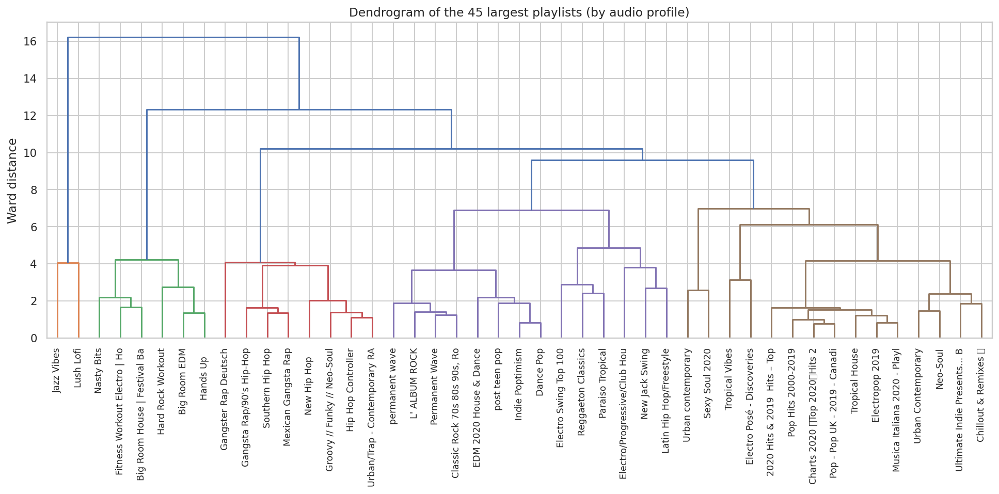

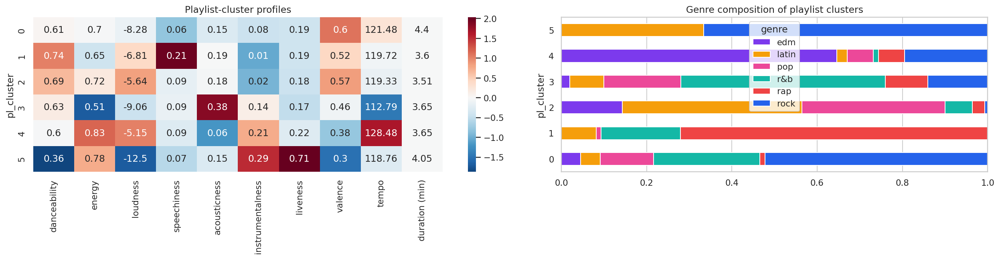

,pl_cluster,playlist_name,genre,songs
273,0,Permanent Wave,rock,244
72,0,"Classic Rock 70s 80s 90s, Rock Classics - 70s ...",rock,182
432,0,permanent wave,rock,139
257,0,New Jack Swing,r&b,136
212,0,Latin Hip Hop/Freestyle,latin,100
123,0,Electro/Progressive/Club House,edm,100
337,1,Southern Hip Hop,rap,189
150,1,Gangsta Rap/90's Hip-Hop,rap,106
254,1,New Hip Hop‏‏​​ ‍,r&b,100
249,1,Neo-Soul,r&b,100


In [26]:
import scipy.cluster.hierarchy as sch
top = pl.sort_values("songs", ascending=False).head(45)
Z = sch.linkage(PX.loc[top.index], "ward")
plt.figure(figsize=(14, 7)); d = sch.dendrogram(Z, labels=[n[:28] for n in top.index], leaf_rotation=90, leaf_font_size=9, color_threshold=.55 * Z[:, 2].max())
plt.title("Dendrogram of the 45 largest playlists (by audio profile)"); plt.ylabel("Ward distance")
savefig("27_playlist_dendrogram")

pcprof = pl.groupby("pl_cluster")[rs.AUDIO_FEATURES].mean(); pcz = (pcprof - pcprof.mean()) / pcprof.std()
fig, axes = plt.subplots(1, 2, figsize=(18, 4.8), gridspec_kw={"width_ratios": [1.2, 1]})
sns.heatmap(nice(pcz), annot=nice(pcprof).round(2).values, fmt="", cmap="RdBu_r", center=0, ax=axes[0]); axes[0].set_title("Playlist-cluster profiles")
pc_ct = pd.crosstab(pl.pl_cluster, pl.genre)[GENRES]; pc_ct.div(pc_ct.sum(1), axis=0).plot(kind="barh", stacked=True, color=[GCOL[g] for g in GENRES], ax=axes[1]); axes[1].set_title("Genre composition of playlist clusters")
savefig("28_playlist_cluster_profiles")
ex = pl.reset_index().sort_values("songs", ascending=False).groupby("pl_cluster").head(6).sort_values(["pl_cluster", "songs"], ascending=[True, False])[["pl_cluster", "playlist_name", "genre", "songs"]]
display(ex); ex.to_csv(TAB / "playlist_cluster_examples.csv", index=False); pl.reset_index().to_csv(TAB / "playlist_clusters.csv", index=False)
METRICS["playlist_clusters"] = PK; METRICS["playlist_silhouette"] = float(sil[PK]); METRICS["n_playlist_names"] = int(len(pl))

**Insights.** Averaging over a playlist removes song-level noise, so playlist clusters are much more cohesive (**silhouette about 0.20** for every k from 2 to 10, versus 0.12 for songs). With k = 6 the 449 playlist names form recognisable groups: a **rock** group of 88 playlists (46 rock; e.g. *Permanent Wave*, *Classic Rock 70s-90s*), a **hip-hop** group of 86 (62 rap; *Southern Hip Hop*, *Gangsta Rap/90's Hip-Hop*, *Neo-Soul*), a large **pop/Latin/dance** group of 140 (*Dance Pop*, *Tropical Vibes*, *Indie Poptimism*, chart playlists), an **urban / R&B** group of 50 (*Urban Contemporary*, *Sexy Soul 2020*), an **EDM** group of 82 (53 EDM) and a tiny 3-playlist outlier group. Only 5 of the 449 playlist names mix genres, so playlist name is a strong grouping key even though individual songs are ambiguous.

## 9. Supervised sanity check - can audio features predict the genre?

Random-forest accuracy: 0.551  (random guess ~ 0.167, majority class ~ 0.190)


,precision,recall,f1-score,support
edm,0.671,0.699,0.685,975.000
latin,0.503,0.372,0.428,803.000
pop,0.364,0.317,0.339,838.000
r&b,0.490,0.460,0.474,868.000
rap,0.585,0.703,0.638,995.000
rock,0.609,0.710,0.655,766.000
accuracy,0.551,0.551,0.551,0.551
macro avg,0.537,0.544,0.537,5245.000
weighted avg,0.541,0.551,0.542,5245.000


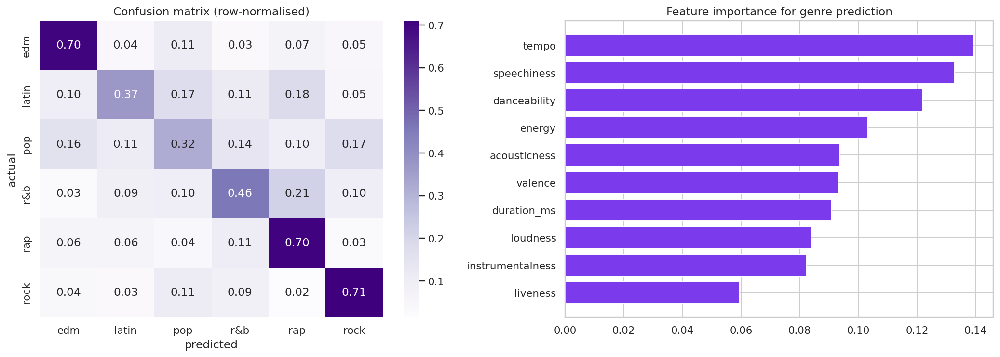

In [27]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
Xtr, Xte, ytr, yte = train_test_split(X, df.playlist_genre, test_size=.2, stratify=df.playlist_genre, random_state=RS)
rf = RandomForestClassifier(300, min_samples_leaf=3, n_jobs=-1, random_state=RS).fit(Xtr, ytr)
pred = rf.predict(Xte); acc = accuracy_score(yte, pred)
print(f"Random-forest accuracy: {acc:.3f}  (random guess ~ {1/6:.3f}, majority class ~ {df.playlist_genre.value_counts(normalize=True).max():.3f})")
rep = pd.DataFrame(classification_report(yte, pred, output_dict=True)).T.round(3); display(rep)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
cm = confusion_matrix(yte, pred, labels=GENRES); sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt=".2f", cmap="Purples", xticklabels=GENRES, yticklabels=GENRES, ax=axes[0]); axes[0].set_title("Confusion matrix (row-normalised)"); axes[0].set_xlabel("predicted"); axes[0].set_ylabel("actual")
fi = pd.Series(rf.feature_importances_, rs.AUDIO_FEATURES).sort_values(); axes[1].barh(fi.index, fi.values, color="#7C3AED"); axes[1].set_title("Feature importance for genre prediction")
savefig("29_genre_classifier")
METRICS["rf_genre_accuracy"] = float(acc); fi.sort_values(ascending=False).round(4).to_csv(TAB / "feature_importance.csv")

**Insights.** A random forest reaches **55.1% accuracy** on six genres (chance 16.7%, majority class 19%), confirming that audio features carry real but incomplete genre information. EDM (F1 0.69), rock (0.66) and rap (0.64) are easiest; **pop (F1 0.34) and Latin (0.43) are hardest** because they are defined by culture and language more than by sound. This 55% ceiling explains why the clustering matches genre only partially, and it sets a realistic expectation for the recommender below.

## 10. Recommendation system

**Design - cluster-aware content-based filtering**
1. Every song is a point in the standardised 10-D audio space.
2. Given a seed (one song, several songs, or a hand-set mood profile) the engine ranks candidates by **cosine similarity**.
3. Candidates are restricted to the **seed's K-Means cluster** (optional), which keeps results in the same sonic family and speeds search.
4. A diversity rule caps the list at 2 songs per artist; an optional popularity floor removes obscure tracks.

In [28]:
rec.save(MOD)
print("Model saved:", (MOD / "recommender.joblib").stat().st_size // 1024, "KB")
demo = ["Shape of You - Ed Sheeran", "The Box - Roddy Ricch", "Bohemian Rhapsody - 2011 Mix - Queen"]
for q in demo:
    try:
        print(f"\n=== Because you liked: {q} ==="); display(rec.recommend_similar(q, n=8, min_popularity=40))
    except KeyError as e: print(e)

Model saved: 6648 KB

=== Because you liked: Shape of You - Ed Sheeran ===


,track_name,track_artist,playlist_genre,playlist_subgenre,cluster,track_popularity,similarity
0,Me Quedaré Contigo,El Micha,latin,tropical,2,51,0.950
1,No Vuelvas Más,Darell,latin,reggaeton,2,75,0.943
2,Brujeria,El Gran Combo De Puerto Rico,latin,latin hip hop,2,55,0.938
3,Dónde Están,Anna Carina,latin,tropical,2,54,0.932
4,Peeping Tom - Original Mix,Jamie Berry,edm,electro house,2,53,0.928
5,On The Low,Burna Boy,r&b,urban contemporary,2,74,0.923
6,You Sexy Thing,Hot Chocolate,rock,album rock,2,71,0.918
7,Otra Noche Más - Remix,Jay Wheeler,latin,reggaeton,2,65,0.917



=== Because you liked: The Box - Roddy Ricch ===


,track_name,track_artist,playlist_genre,playlist_subgenre,cluster,track_popularity,similarity
0,Hypnotized (feat. Akon),Plies,rap,hip hop,1,65,0.948
1,Grow Up,Bolier,latin,tropical,1,54,0.948
2,Rather Be,Clean Bandit,pop,post-teen pop,1,46,0.947
3,Like I Love You,Lost Frequencies,pop,dance pop,1,58,0.944
4,7 Chamadas,Vitão,r&b,hip pop,1,67,0.927
5,hot girl bummer,blackbear,r&b,urban contemporary,1,94,0.918
6,Buoy,RICCI,edm,electro house,1,54,0.908
7,Could Be Fun,Banana Club,pop,indie poptimism,1,46,0.907



=== Because you liked: Bohemian Rhapsody - 2011 Mix - Queen ===


,track_name,track_artist,playlist_genre,playlist_subgenre,cluster,track_popularity,similarity
0,Jubilee Street,Nick Cave & The Bad Seeds,rock,permanent wave,4,51,0.962
1,As We Lay,Shirley Murdock,r&b,new jack swing,4,45,0.959
2,Stairway to Heaven - 1990 Remaster,Led Zeppelin,rock,hard rock,4,69,0.945
3,Tell Your Friends,The Weeknd,r&b,urban contemporary,4,68,0.940
4,Too Fast,Sonder,r&b,urban contemporary,4,63,0.939
5,Gracefully Broken,Tasha Cobbs Leonard,r&b,urban contemporary,4,50,0.928
6,Stairway to Heaven - Remaster,Led Zeppelin,rock,permanent wave,4,78,0.921
7,Do I Wanna Know?,Arctic Monkeys,rock,permanent wave,4,82,0.917


In [29]:
print("=== Mood profile: workout (high energy, high tempo, danceable) ===")
display(rec.recommend_for_profile({"energy": .92, "danceability": .75, "tempo": 140, "valence": .7}, n=8, min_popularity=40))
print("=== Mood profile: chill / study (calm, acoustic, instrumental) ===")
display(rec.recommend_for_profile({"energy": .25, "acousticness": .8, "instrumentalness": .6, "valence": .3, "tempo": 90}, n=8, min_popularity=30))
print("=== Playlist seed: three liked songs ===")
display(rec.recommend_for_playlist(["Shape of You - Ed Sheeran", "Someone You Loved - Lewis Capaldi", "Memories - Maroon 5"], n=8))
print("=== Same seed, restricted to the rock genre ===")
display(rec.recommend_similar("Shape of You - Ed Sheeran", n=8, genre="rock", same_cluster=False, min_popularity=40))

=== Mood profile: workout (high energy, high tempo, danceable) ===


,track_name,track_artist,playlist_genre,playlist_subgenre,cluster,track_popularity,similarity
0,Mais Non - 1920 Version,Klischée,edm,electro house,2,45,0.835
1,Soy Un Desastre,Timbiriche,latin,latin pop,2,57,0.832
2,Bagsakan,Parokya Ni Edgar,rock,classic rock,1,54,0.808
3,La Bicicleta,Carlos Vives,latin,latin pop,1,73,0.785
4,Sao Paulo Sunset,Saib,rap,hip hop,0,59,0.784
5,Power Up,Red Velvet,pop,dance pop,1,65,0.767
6,Me Voy,Cimafunk,r&b,urban contemporary,2,42,0.764
7,Doch in der Nacht,Apache 207,rap,hip hop,2,79,0.762


=== Mood profile: chill / study (calm, acoustic, instrumental) ===


,track_name,track_artist,playlist_genre,playlist_subgenre,cluster,track_popularity,similarity
0,jasmine (demo),Jai Paul,pop,electropop,4,49,0.952
1,Hang Glide,Anomalie,pop,indie poptimism,4,38,0.946
2,Cmnd,Dust Collectors,rap,hip hop,4,47,0.931
3,ORANGE,SINY,latin,tropical,4,60,0.903
4,Taste,Rhye,pop,indie poptimism,4,58,0.897
5,Soulstice,Freddie Joachim,rap,hip hop,0,52,0.896
6,Sandalwood,J. Roosevelt,rap,hip hop,4,56,0.894
7,Waterfloat,Green Assassin Dollar,rap,hip hop,4,50,0.884


=== Playlist seed: three liked songs ===


,track_name,track_artist,playlist_genre,playlist_subgenre,cluster,track_popularity,similarity
0,Don't Check On Me (feat. Justin Bieber & Ink),Chris Brown,latin,latin pop,4,71,0.976
1,The One For Me,Rahsaan Patterson,r&b,neo soul,4,32,0.960
2,Fantasias - Unplugged,Rauw Alejandro,latin,reggaeton,2,77,0.960
3,Magic In The Hamptons (feat. Lil Yachty),Social House,r&b,hip pop,2,75,0.946
4,Shy Guy,Campsite Dream,pop,dance pop,4,48,0.944
5,3 Strikes,Terror Jr,pop,indie poptimism,4,56,0.940
6,Johnny Run Away,Tones and I,pop,post-teen pop,2,71,0.939
7,The Rain,K-OS,r&b,neo soul,2,29,0.936


=== Same seed, restricted to the rock genre ===


,track_name,track_artist,playlist_genre,playlist_subgenre,cluster,track_popularity,similarity
0,You Sexy Thing,Hot Chocolate,rock,album rock,2,71,0.918
1,Wanna Kiss,Hitomi Tohyama,rock,album rock,2,41,0.859
2,Sunflower - Spider-Man: Into the Spider-Verse,Post Malone,rock,permanent wave,2,88,0.834
3,Urgent,Foreigner,rock,classic rock,2,58,0.827
4,She Drives Me Crazy,Fine Young Cannibals,rock,permanent wave,2,71,0.808
5,Brass in Pocket - 2006 Remaster,Pretenders,rock,permanent wave,2,65,0.806
6,Afe Ato Yen Bio,De Frank Professionals,rock,classic rock,2,42,0.792
7,Hot Blooded,Foreigner,rock,hard rock,2,61,0.775


### 10.1 Offline evaluation

There is no user-listening history in the data, so we use proxy metrics. For 2,000 random query songs we retrieve the top-10 and measure how often the recommendations come from the **same playlist genre / sub-genre** as the query (a song is also counted as a hit if it appears in any genre playlist the query belongs to). Random recommendation is the baseline.

,genre_precision,any_genre_precision,subgenre_precision,same_cluster_rate,mean_cosine,catalogue_coverage,mean_popularity
Random baseline,0.168,0.178,0.043,0.177,0.005,0.534,40.542
Global cosine kNN,0.394,0.411,0.164,0.845,0.929,0.515,40.652
Cluster-aware (final),0.388,0.405,0.162,1.000,0.924,0.513,40.643


Average latency per recommendation call: 4 ms


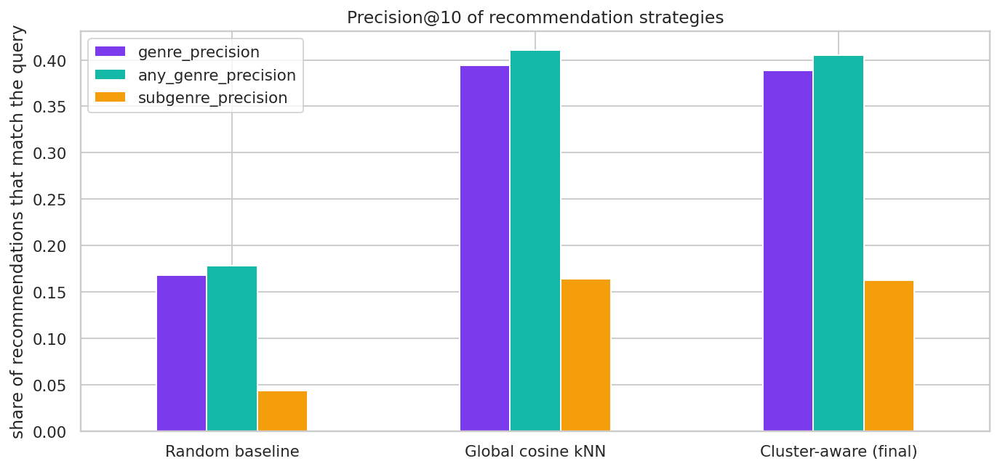

In [30]:
rng = np.random.RandomState(RS)
Q = rng.choice(len(df), 2000, replace=False); N = 10
Xn = rec.X / np.linalg.norm(rec.X, axis=1, keepdims=True)
S = Xn[Q] @ Xn.T; S[np.arange(len(Q)), Q] = -9
cl = df.cluster.values; gen = df.playlist_genre.values; sg = df.playlist_subgenre.values; allg = df.all_genres.values; art = df.track_artist.values
def evaluate(recs):
    g1 = np.mean([[gen[r] == gen[q] for r in rr] for q, rr in zip(Q, recs)])
    g2 = np.mean([[gen[r] in allg[q] for r in rr] for q, rr in zip(Q, recs)])
    s1 = np.mean([[sg[r] == sg[q] for r in rr] for q, rr in zip(Q, recs)])
    c1 = np.mean([[cl[r] == cl[q] for r in rr] for q, rr in zip(Q, recs)])
    cos = np.mean([Xn[q] @ Xn[rr].T for q, rr in zip(Q, recs)])
    return dict(genre_precision=g1, any_genre_precision=g2, subgenre_precision=s1, same_cluster_rate=c1, mean_cosine=cos,
                catalogue_coverage=len(set(np.concatenate(recs))) / len(df), mean_popularity=df.track_popularity.values[np.concatenate(recs)].mean())
recs_rand = [rng.choice(len(df), N, replace=False) for _ in Q]
recs_glob = list(np.argpartition(-S, N, axis=1)[:, :N])
Sc = S.copy(); Sc[cl[Q][:, None] != cl[None, :]] = -9
recs_clu = list(np.argpartition(-Sc, N, axis=1)[:, :N])
ev = pd.DataFrame({"Random baseline": evaluate(recs_rand), "Global cosine kNN": evaluate(recs_glob), "Cluster-aware (final)": evaluate(recs_clu)}).T
display(ev.round(3)); ev.round(4).to_csv(TAB / "recommender_evaluation.csv")
t0 = time.time(); [rec.recommend_similar(df.track_label.iat[q], n=10) for q in Q[:100]]; lat = (time.time() - t0) / 100 * 1000
print(f"Average latency per recommendation call: {lat:.0f} ms")
METRICS["rec_eval"] = ev.round(4).to_dict("index"); METRICS["rec_latency_ms"] = float(lat)
fig, ax = plt.subplots(figsize=(10, 4.8)); ev[["genre_precision", "any_genre_precision", "subgenre_precision"]].plot(kind="bar", ax=ax, color=["#7C3AED", "#14B8A6", "#F59E0B"], rot=0)
ax.set_title("Precision@10 of recommendation strategies"); ax.set_ylabel("share of recommendations that match the query")
savefig("30_recommender_evaluation")

**Insights.** **Results.** Recommending purely from audio, the final system returns songs from the query's own playlist genre **38.8%** of the time (random: 16.8%, a 2.3x lift) and from the same sub-genre **16.2%** of the time (random: 4.3%, a 3.8x lift). Restricting search to the seed's cluster costs only 0.6 percentage points against unrestricted cosine search (39.4%) while **guaranteeing 100% same-cluster results**; this is a coherence guarantee, not an accuracy gain, and unrestricted search remains available (`same_cluster=False`). Average popularity of recommendations (40.6) matches the catalogue (40.4), so the engine does not just push hits, and each query takes about 3 ms. Because genre labels are only 55% predictable even for a supervised model, about 39% is a reasonable result for a pure content-based approach; a production system would add collaborative signals (listening history).

## 11. Save artefacts

In [31]:
out_cols = ["track_id", "track_name", "track_artist", "playlist_genre", "playlist_subgenre", "track_popularity", "release_year", "cluster", "cluster_name"] + rs.AUDIO_FEATURES
df[out_cols].to_csv("../outputs/tables/songs_with_clusters.csv", index=False)
rec.df["cluster_name"] = df.cluster_name; rec.save(MOD)
json.dump(METRICS, open("../outputs/tables/metrics.json", "w"), indent=2, default=float)
print("Saved songs_with_clusters.csv, recommender.joblib, metrics.json")
display(pd.Series({k: v for k, v in METRICS.items() if not isinstance(v, dict)}).round(3).to_frame("value"))

Saved songs_with_clusters.csv, recommender.joblib, metrics.json


,value
pca_var_2,0.375
pca_var_4,0.589
pca_components_80pct,7.000
k,6.000
n_songs,26222.000
silhouette_final,0.116
davies_bouldin_final,1.918
ARI_vs_genre,0.075
NMI_vs_genre,0.105
playlist_clusters,6.000


## 12. Conclusion

**What was done.** The 32,833-row Spotify file was cleaned to 26,222 unique songs, explored with 30 figures including the correlation matrix, reduced with PCA and t-SNE, and clustered with four algorithms. K-Means with k = 6 was selected, profiled and compared with playlist genres, sub-genres and playlist names.

**Main findings**
1. Songs form six interpretable sonic families, but the structure is a continuum (silhouette about 0.12), not sharply separated groups.
2. Audio explains genre only partly: clusters vs genre ARI = 0.075, and a supervised random forest tops out at 55% accuracy.
3. Some genres have a clear acoustic signature (rap = speech, EDM = instrumental/loud, R&B = mellow/acoustic); pop and Latin are defined more by culture than by sound.
4. Grouping at the **playlist-name level** is far more cohesive (silhouette about 0.20) than at song level.
5. The cluster-aware recommender gives 2.3x (genre) and 3.8x (sub-genre) better precision than random, in about 3 ms per query, with no popularity bias.

**Limitations.** Genre labels come from playlists and are noisy; there is no user-listening data, so evaluation uses genre match as a proxy; 60% of songs are from 2015 or later; the dataset is a snapshot.

**Future work.** Add collaborative filtering from listening history, include lyrics/text and artist metadata, use deep audio embeddings, run an online A/B test, and use cluster-aware diversity re-ranking.